# Self Learning Tutorial
**Predicting Home-Based vs. Facility-Based Discharge Using MIMIC-IV Early Hospitalization Data**

Hospital discharge delays are a major driver of length-of-stay inefficiencies, bed capacity bottlenecks, and inflated healthcare expenditures. For patients recovering from acute or critical illness, transitioning to post-acute care (PAC), including skilled nursing facilities, acute rehabilitation, or long-term care, requires extensive coordination, insurance authorization, and family alignment. When PAC needs are identified late in an admission, patients often occupy acute care beds days longer than clinically necessary while waiting for placement.

**Our research question:** Can demographic, admission, and laboratory information available within the first 24 hours of hospitalization predict whether an adult patient will ultimately have a home-based or facility-based discharge?

This tutorial explores whether early hospitalization data could potentially support earlier discharge-planning risk stratification and illustrates the machine-learning workflow needed to evaluate such a prediction task.

**Note:** This tutorial uses the [MIMIC-IV](https://physionet.org/content/mimiciv/3.1/) dataset which requires credentialed access for use. Additionally, we are using BigQuery via Colab in this notebook for data extraction. Follow these [instructions](https://mimic.mit.edu/docs/gettingstarted/cloud/link.html) to access MIMIC-IV via BigQuery and make sure to use the same email for both Colab and BigQuery when executing this notebook.

In [7]:
# Authenticate in Google Cloud
from google.colab import auth

auth.authenticate_user()

# Connect to BigQuery project
from google.cloud import bigquery

# Replace with your Google Cloud project ID with MIMIC-IV BigQuery access
project_id = "GOOGLE_CLOUD_PROJECT_ID"
client = bigquery.Client(project=project_id)


## Defining the Prediction Outcome

The goal of this tutorial is to predict an **observed hospital discharge destination** using information available during the first 24 hours of hospitalization.

We divide eligible discharge destinations into two groups:

- **Home-based discharge (0):** `HOME`, `HOME HEALTH CARE`
- **Facility-based discharge (1):** `SKILLED NURSING FACILITY`, `REHAB`, `CHRONIC/LONG TERM ACUTE CARE`, `ASSISTED LIVING`

Other discharge destinations are excluded because they represent different clinical pathways or are difficult to interpret consistently for this prediction task. For example, death and hospice reflect end-of-life pathways, acute-hospital transfer represents continued acute care, and psychiatric-facility discharge represents a different type of care transition.

An important limitation is that this outcome records **where the patient was discharged**, not whether the patient developed a new need for post-acute placement. For example, a patient admitted from a skilled nursing facility may simply return to that facility. Therefore, throughout this tutorial, "facility-based discharge" refers to the observed destination rather than a causal or clinical determination that a new facility placement was required.

In [8]:
# Inspect discharge categories
discharge_sql = """
SELECT
    discharge_location,
    COUNT(*) AS n_admissions
FROM `physionet-data.mimiciv_3_1_hosp.admissions`
GROUP BY discharge_location
ORDER BY n_admissions DESC
"""

discharge_counts = client.query(discharge_sql).to_dataframe()
display(discharge_counts)


,discharge_location,n_admissions
0,HOME,194204
1,None,149818
2,HOME HEALTH CARE,99305
3,SKILLED NURSING FACILITY,52657
4,REHAB,13845
5,DIED,11721
6,CHRONIC/LONG TERM ACUTE CARE,8125
7,HOSPICE,5397
8,AGAINST ADVICE,3393
9,PSYCH FACILITY,2965


## Defining Our Cohort

The cohort is designed around a prediction time of **24 hours after hospital admission**. Each row represents one hospitalization (`hadm_id`).

Admissions are included when the patient:

- is an adult at admission,
- survives the hospitalization,
- remains hospitalized for at least 24 hours,
- has one of the discharge destinations included in our binary outcome definition.

Only information available at admission or during the first 24 hours is used as a predictor. This helps prevent **data leakage**, which would occur if information that became available later in the hospital stay were used to predict the eventual discharge destination.

Age is calculated using MIMIC-IV's `anchor_age` and `anchor_year`. Because MIMIC-IV de-identifies very old ages, calculated ages greater than 89 are grouped at 91 rather than treated as exact ages.

Variables such as total length of stay, discharge summaries, late procedures, post-24-hour laboratory results, and discharge-time information are deliberately excluded from the predictor set because they would reveal information unavailable at the intended prediction time.

In [9]:
# Define the cohort once so it can be reused in later BigQuery queries

cohort_sql = """
SELECT
    a.subject_id,
    a.hadm_id,
    a.admittime,
    a.dischtime,

    -- End of the 24-hour feature window
    TIMESTAMP_ADD(a.admittime, INTERVAL 24 HOUR) AS prediction_time,

    -- Age at admission; patients older than 89 grouped as 91
    CASE
        WHEN (
            p.anchor_age
            + EXTRACT(YEAR FROM a.admittime)
            - p.anchor_year
        ) > 89
        THEN 91

        ELSE (
            p.anchor_age
            + EXTRACT(YEAR FROM a.admittime)
            - p.anchor_year
        )
    END AS age,

    p.gender AS sex,

    a.admission_type,
    a.admission_location,
    a.insurance,
    a.marital_status,

    a.discharge_location,
    a.hospital_expire_flag,

    -- For cohort validation only; NOT a model feature
    TIMESTAMP_DIFF(a.dischtime, a.admittime, HOUR) AS hospital_los_hours,

    -- Prediction target
    CASE
        WHEN a.discharge_location IN (
            'HOME',
            'HOME HEALTH CARE'
        ) THEN 0

        WHEN a.discharge_location IN (
            'SKILLED NURSING FACILITY',
            'REHAB',
            'CHRONIC/LONG TERM ACUTE CARE',
            'ASSISTED LIVING'
        ) THEN 1
    END AS facility_discharge

FROM `physionet-data.mimiciv_3_1_hosp.admissions` a

INNER JOIN `physionet-data.mimiciv_3_1_hosp.patients` p
    ON a.subject_id = p.subject_id

WHERE
    a.dischtime IS NOT NULL

    -- Must remain hospitalized for at least 24 hours
    AND TIMESTAMP_DIFF(a.dischtime, a.admittime, HOUR) >= 24

    -- Exclude in-hospital deaths
    AND a.hospital_expire_flag = 0

    -- Keep only our defined outcome groups
    AND a.discharge_location IN (
        'HOME',
        'HOME HEALTH CARE',
        'SKILLED NURSING FACILITY',
        'REHAB',
        'CHRONIC/LONG TERM ACUTE CARE',
        'ASSISTED LIVING'
    )

    -- Adults only
    AND (
        p.anchor_age
        + EXTRACT(YEAR FROM a.admittime)
        - p.anchor_year
    ) >= 18
"""

cohort = client.query(cohort_sql + "\nORDER BY subject_id, admittime").to_dataframe()

print("Hospitalizations:", len(cohort))
print("Unique patients:", cohort["subject_id"].nunique())

print("Cohort shape:", cohort.shape)
print("Columns:")
print(cohort.columns.tolist())


Hospitalizations: 350699
Unique patients: 163555
Cohort shape: (350699, 15)
Columns:
['subject_id', 'hadm_id', 'admittime', 'dischtime', 'prediction_time', 'age', 'sex', 'admission_type', 'admission_location', 'insurance', 'marital_status', 'discharge_location', 'hospital_expire_flag', 'hospital_los_hours', 'facility_discharge']


In [10]:
# Check the resulting cohort balance

print(cohort["facility_discharge"].value_counts())
print()
print(cohort["facility_discharge"].value_counts(normalize=True))


facility_discharge
0    276073
1     74626
Name: count, dtype: Int64

facility_discharge
0    0.787208
1    0.212792
Name: proportion, dtype: Float64


In [11]:
# Check discharge location counts

target_summary = (
    cohort.groupby(["facility_discharge", "discharge_location"])
    .size()
    .reset_index(name="n")
    .sort_values(["facility_discharge", "n"], ascending=[True, False])
)

display(target_summary)


,facility_discharge,discharge_location,n
0,0,HOME,178385
1,0,HOME HEALTH CARE,97688
5,1,SKILLED NURSING FACILITY,52182
4,1,REHAB,13802
3,1,CHRONIC/LONG TERM ACUTE CARE,8064
2,1,ASSISTED LIVING,578


In [12]:
# Check ambiguous destination counts

ambgidest_sql = """
SELECT
    discharge_location,
    COUNT(*) AS n
FROM `physionet-data.mimiciv_3_1_hosp.admissions`
WHERE discharge_location IN (
    'HEALTHCARE FACILITY',
    'OTHER FACILITY'
)
GROUP BY discharge_location
ORDER BY n DESC
"""

ambiguous_destinations = client.query(ambgidest_sql).to_dataframe()
display(ambiguous_destinations)


,discharge_location,n
0,OTHER FACILITY,1592
1,HEALTHCARE FACILITY,50


### Cohort Summary

The final cohort contains **350,699 hospitalizations from 163,555 unique patients**.

The outcome is moderately imbalanced:

- **276,073 admissions (78.7%)** ended in a home-based discharge.
- **74,626 admissions (21.3%)** ended in a facility-based discharge.

This imbalance is important when evaluating the models. A classifier could achieve relatively high overall accuracy simply by predicting the more common home-based outcome most of the time. For that reason, later model evaluation will consider not only accuracy, but also **precision, recall, F1 score, ROC-AUC, and PR-AUC**.

The facility-based group is primarily composed of skilled nursing facility discharges, followed by rehabilitation and chronic/long-term acute care. Assisted living represents a much smaller portion of the positive outcome.

In [13]:
# Identify candidate itemid's from d_labitems

labcand_sql = """
SELECT
    itemid,
    label,
    fluid,
    category
FROM `physionet-data.mimiciv_3_1_hosp.d_labitems`
WHERE
    LOWER(fluid) = 'blood'
    AND REGEXP_CONTAINS(
        LOWER(label),
        r'wbc|white blood|hemoglobin|platelet|sodium|potassium|creatinine|urea nitrogen|bun|glucose|bicarbonate'
    )
ORDER BY label, itemid
"""

lab_candidates = client.query(labcand_sql).to_dataframe()
display(lab_candidates)


,itemid,label,fluid,category
0,50852,% Hemoglobin A1c,Blood,Chemistry
1,50855,Absolute Hemoglobin,Blood,Chemistry
2,50882,Bicarbonate,Blood,Chemistry
3,50803,"Calculated Bicarbonate, Whole Blood",Blood,Blood Gas
4,50805,Carboxyhemoglobin,Blood,Blood Gas
5,50912,Creatinine,Blood,Chemistry
6,52546,Creatinine,Blood,Chemistry
7,52024,"Creatinine, Whole Blood",Blood,Blood Gas
8,52105,Direct Antiplatelet Antibodies,Blood,Hematology
9,51212,Fetal Hemoglobin,Blood,Hematology


### Selecting First-24-Hour Laboratory Features

We will use nine commonly measured blood laboratory tests:

**White blood cells, hemoglobin, platelet count, sodium, potassium, creatinine, blood urea nitrogen (BUN), glucose, and bicarbonate.**

For each laboratory, all numeric measurements recorded from admission through the first 24 hours are summarized using four features:

- `first`: earliest available measurement,
- `min`: minimum value,
- `max`: maximum value,
- `mean`: average value.

This produces **36 laboratory predictors** (9 laboratory tests × 4 summary statistics).

Using several summaries allows the model to represent both the patient's initial laboratory state and the range of measurements observed during the first hospital day. However, these summaries are likely to be correlated with one another. We will examine that during exploratory analysis and later test whether Principal Component Analysis (PCA) can reduce this redundancy.

In [14]:
# Validate IDs against v3.1 database

lab_itemids = [
    51301,  # WBC
    51222,  # Hemoglobin
    51265,  # Platelet count
    50983,  # Sodium
    50971,  # Potassium
    50912,  # Creatinine
    51006,  # BUN / Urea Nitrogen
    50931,  # Glucose
    50882,  # Bicarbonate
]

itemid_string = ",".join(map(str, lab_itemids))

labs_sql = f"""
SELECT
    itemid,
    label,
    fluid,
    category
FROM `physionet-data.mimiciv_3_1_hosp.d_labitems`
WHERE itemid IN ({itemid_string})
ORDER BY itemid
"""

selected_labs = client.query(labs_sql).to_dataframe()
display(selected_labs)


,itemid,label,fluid,category
0,50882,Bicarbonate,Blood,Chemistry
1,50912,Creatinine,Blood,Chemistry
2,50931,Glucose,Blood,Chemistry
3,50971,Potassium,Blood,Chemistry
4,50983,Sodium,Blood,Chemistry
5,51006,Urea Nitrogen,Blood,Chemistry
6,51222,Hemoglobin,Blood,Hematology
7,51265,Platelet Count,Blood,Hematology
8,51301,White Blood Cells,Blood,Hematology


In [15]:
# First 24 hour coverage

coverage_sql = """
WITH cohort AS (
    SELECT
        a.subject_id,
        a.hadm_id,
        a.admittime,
        TIMESTAMP_ADD(a.admittime, INTERVAL 24 HOUR) AS prediction_time,

        -- Age at admission; patients older than 89 grouped as 91
        CASE
            WHEN (
                p.anchor_age
                + EXTRACT(YEAR FROM a.admittime)
                - p.anchor_year
            ) > 89
            THEN 91

            ELSE (
                p.anchor_age
                + EXTRACT(YEAR FROM a.admittime)
                - p.anchor_year
            )
        END AS age

    FROM `physionet-data.mimiciv_3_1_hosp.admissions` a

    INNER JOIN `physionet-data.mimiciv_3_1_hosp.patients` p
        ON a.subject_id = p.subject_id

    WHERE
        a.dischtime IS NOT NULL
        AND TIMESTAMP_DIFF(a.dischtime, a.admittime, HOUR) >= 24
        AND a.hospital_expire_flag = 0

        AND a.discharge_location IN (
            'HOME',
            'HOME HEALTH CARE',
            'SKILLED NURSING FACILITY',
            'REHAB',
            'CHRONIC/LONG TERM ACUTE CARE',
            'ASSISTED LIVING'
        )

        AND (
            p.anchor_age
            + EXTRACT(YEAR FROM a.admittime)
            - p.anchor_year
        ) >= 18
)

SELECT
    le.itemid,
    d.label,

    COUNT(*) AS n_measurements,

    COUNT(DISTINCT le.hadm_id) AS admissions_with_lab,

    ROUND(
        100.0 * COUNT(DISTINCT le.hadm_id)
        / (SELECT COUNT(*) FROM cohort),
        1
    ) AS pct_admissions_with_lab

FROM cohort c

INNER JOIN `physionet-data.mimiciv_3_1_hosp.labevents` le
    ON c.hadm_id = le.hadm_id
    AND le.charttime >= c.admittime
    AND le.charttime < c.prediction_time

INNER JOIN `physionet-data.mimiciv_3_1_hosp.d_labitems` d
    ON le.itemid = d.itemid

WHERE
    le.itemid IN (
        51301, -- WBC
        51222, -- Hemoglobin
        51265, -- Platelets
        50983, -- Sodium
        50971, -- Potassium
        50912, -- Creatinine
        51006, -- BUN
        50931, -- Glucose
        50882 -- Bicarbonate
    )

    AND le.valuenum IS NOT NULL

GROUP BY
    le.itemid,
    d.label

ORDER BY
    pct_admissions_with_lab DESC
"""

lab_coverage = client.query(coverage_sql).to_dataframe()
display(lab_coverage)


,itemid,label,n_measurements,admissions_with_lab,pct_admissions_with_lab
0,51265,Platelet Count,391917,282886,80.7
1,51222,Hemoglobin,389766,282579,80.6
2,51301,White Blood Cells,387318,282557,80.6
3,50912,Creatinine,389330,275163,78.5
4,50971,Potassium,396385,273240,77.9
5,51006,Urea Nitrogen,384456,272362,77.7
6,50983,Sodium,390464,271081,77.3
7,50882,Bicarbonate,381325,270691,77.2
8,50931,Glucose,373644,268463,76.6


In [16]:
# Create a single hospitalization level modeling dataframe
# cohort --> summarize each lab within 24 hours --> pivot lab summaries to
# one row per admission

model_sql = f"""
WITH cohort AS (

    -- Reuse the cohort definition created earlier
    {cohort_sql}

),

first_day_labs AS (

    -- Extract the selected labs during the first 24 hours
    SELECT
        c.hadm_id,
        le.itemid,
        le.charttime,
        le.storetime,
        le.valuenum

    FROM cohort c

    INNER JOIN `physionet-data.mimiciv_3_1_hosp.labevents` le
        ON c.hadm_id = le.hadm_id

    WHERE
        le.charttime >= c.admittime
        AND le.charttime < c.prediction_time

        -- Reuse the lab IDs identified earlier
        AND le.itemid IN ({itemid_string})

        AND le.valuenum IS NOT NULL
),

lab_summary AS (

    SELECT
        hadm_id,
        itemid,

        ARRAY_AGG(
            valuenum
            ORDER BY charttime, storetime
            LIMIT 1
        )[SAFE_OFFSET(0)] AS first_value,

        MIN(valuenum) AS min_value,
        MAX(valuenum) AS max_value,
        AVG(valuenum) AS mean_value

    FROM first_day_labs

    GROUP BY hadm_id, itemid
),

lab_features AS (

    SELECT
        hadm_id,

        -- White Blood Cells
        MAX(IF(itemid = 51301, first_value, NULL)) AS wbc_first,
        MAX(IF(itemid = 51301, min_value, NULL))   AS wbc_min,
        MAX(IF(itemid = 51301, max_value, NULL))   AS wbc_max,
        MAX(IF(itemid = 51301, mean_value, NULL))  AS wbc_mean,

        -- Hemoglobin
        MAX(IF(itemid = 51222, first_value, NULL)) AS hemoglobin_first,
        MAX(IF(itemid = 51222, min_value, NULL))   AS hemoglobin_min,
        MAX(IF(itemid = 51222, max_value, NULL))   AS hemoglobin_max,
        MAX(IF(itemid = 51222, mean_value, NULL))  AS hemoglobin_mean,

        -- Platelets
        MAX(IF(itemid = 51265, first_value, NULL)) AS platelet_first,
        MAX(IF(itemid = 51265, min_value, NULL))   AS platelet_min,
        MAX(IF(itemid = 51265, max_value, NULL))   AS platelet_max,
        MAX(IF(itemid = 51265, mean_value, NULL))  AS platelet_mean,

        -- Sodium
        MAX(IF(itemid = 50983, first_value, NULL)) AS sodium_first,
        MAX(IF(itemid = 50983, min_value, NULL))   AS sodium_min,
        MAX(IF(itemid = 50983, max_value, NULL))   AS sodium_max,
        MAX(IF(itemid = 50983, mean_value, NULL))  AS sodium_mean,

        -- Potassium
        MAX(IF(itemid = 50971, first_value, NULL)) AS potassium_first,
        MAX(IF(itemid = 50971, min_value, NULL))   AS potassium_min,
        MAX(IF(itemid = 50971, max_value, NULL))   AS potassium_max,
        MAX(IF(itemid = 50971, mean_value, NULL))  AS potassium_mean,

        -- Creatinine
        MAX(IF(itemid = 50912, first_value, NULL)) AS creatinine_first,
        MAX(IF(itemid = 50912, min_value, NULL))   AS creatinine_min,
        MAX(IF(itemid = 50912, max_value, NULL))   AS creatinine_max,
        MAX(IF(itemid = 50912, mean_value, NULL))  AS creatinine_mean,

        -- BUN
        MAX(IF(itemid = 51006, first_value, NULL)) AS bun_first,
        MAX(IF(itemid = 51006, min_value, NULL))   AS bun_min,
        MAX(IF(itemid = 51006, max_value, NULL))   AS bun_max,
        MAX(IF(itemid = 51006, mean_value, NULL))  AS bun_mean,

        -- Glucose
        MAX(IF(itemid = 50931, first_value, NULL)) AS glucose_first,
        MAX(IF(itemid = 50931, min_value, NULL))   AS glucose_min,
        MAX(IF(itemid = 50931, max_value, NULL))   AS glucose_max,
        MAX(IF(itemid = 50931, mean_value, NULL))  AS glucose_mean,

        -- Bicarbonate
        MAX(IF(itemid = 50882, first_value, NULL)) AS bicarbonate_first,
        MAX(IF(itemid = 50882, min_value, NULL))   AS bicarbonate_min,
        MAX(IF(itemid = 50882, max_value, NULL))   AS bicarbonate_max,
        MAX(IF(itemid = 50882, mean_value, NULL))  AS bicarbonate_mean

    FROM lab_summary
    GROUP BY hadm_id
)

SELECT
    c.subject_id,
    c.hadm_id,

    c.age,
    c.sex,
    c.admission_type,
    c.admission_location,
    c.insurance,
    c.marital_status,

    -- All 36 lab features
    lf.* EXCEPT(hadm_id),

    c.facility_discharge

FROM cohort c

LEFT JOIN lab_features lf
    ON c.hadm_id = lf.hadm_id

ORDER BY c.subject_id, c.hadm_id
"""

model_df = client.query(model_sql).to_dataframe()

print("Modeling dataframe shape:", model_df.shape)
print("Columns:")
print(model_df.columns.tolist())


Modeling dataframe shape: (350699, 45)
Columns:
['subject_id', 'hadm_id', 'age', 'sex', 'admission_type', 'admission_location', 'insurance', 'marital_status', 'wbc_first', 'wbc_min', 'wbc_max', 'wbc_mean', 'hemoglobin_first', 'hemoglobin_min', 'hemoglobin_max', 'hemoglobin_mean', 'platelet_first', 'platelet_min', 'platelet_max', 'platelet_mean', 'sodium_first', 'sodium_min', 'sodium_max', 'sodium_mean', 'potassium_first', 'potassium_min', 'potassium_max', 'potassium_mean', 'creatinine_first', 'creatinine_min', 'creatinine_max', 'creatinine_mean', 'bun_first', 'bun_min', 'bun_max', 'bun_mean', 'glucose_first', 'glucose_min', 'glucose_max', 'glucose_mean', 'bicarbonate_first', 'bicarbonate_min', 'bicarbonate_max', 'bicarbonate_mean', 'facility_discharge']


In [17]:
# Inspect model_df properties

# Number of rows and columns
print("Shape:", model_df.shape)

# Each hadm_id should occur exactly once
print("Unique admissions:", model_df["hadm_id"].nunique())
print("Duplicate hadm_ids:", model_df["hadm_id"].duplicated().sum())

# Number of individual patients
print("Unique patients:", model_df["subject_id"].nunique())

# Outcome balance
print("\nOutcome counts:")
print(model_df["facility_discharge"].value_counts())

print("\nOutcome proportions:")
print(model_df["facility_discharge"].value_counts(normalize=True))


Shape: (350699, 45)
Unique admissions: 350699
Duplicate hadm_ids: 0
Unique patients: 163555

Outcome counts:
facility_discharge
0    276073
1     74626
Name: count, dtype: Int64

Outcome proportions:
facility_discharge
0    0.787208
1    0.212792
Name: proportion, dtype: Float64


### Final Hospitalization-Level Modeling Dataset

The extraction process produces a dataframe with **one row per hospitalization**. There are 350,699 rows and no duplicate `hadm_id` values, confirming that each eligible admission appears exactly once.

The predictor set contains:

- **1 numerical admission variable:** age,
- **5 categorical admission variables:** sex, admission type, admission location, insurance, and marital status,
- **36 first-24-hour laboratory features**.

`subject_id` and `hadm_id` are retained only for identification and patient-level data splitting; they are not used as predictors.

Missing laboratory values are intentionally retained at this stage. A missing laboratory measurement can occur because a test was not ordered or not recorded during the first 24 hours. Dropping all admissions with missing labs would remove a substantial portion of the cohort and could introduce selection bias. Missing values will instead be handled during preprocessing using values learned from the training data only.

In [18]:
# Inspect missingness of the 36 lab variables

lab_columns = [
    col
    for col in model_df.columns
    if any(
        col.startswith(lab)
        for lab in [
            "wbc",
            "hemoglobin",
            "platelet",
            "sodium",
            "potassium",
            "creatinine",
            "bun",
            "glucose",
            "bicarbonate",
        ]
    )
]

missing_summary = (
    model_df[lab_columns]
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .to_frame("missing_percent")
)

display(missing_summary)


,missing_percent
glucose_mean,23.449169
glucose_max,23.449169
glucose_min,23.449169
glucose_first,23.449169
bicarbonate_first,22.813866
bicarbonate_min,22.813866
bicarbonate_max,22.813866
bicarbonate_mean,22.813866
sodium_mean,22.702660
sodium_max,22.702660


## Exploratory Data Analysis (EDA)

Before training a machine-learning model, we examine the cohort to understand the outcome distribution, relationships between admission-time variables and discharge destination, laboratory missingness, extreme values, and correlations among laboratory features.

EDA is used here to guide preprocessing and model design rather than to make causal claims. The relationships shown below are **unadjusted associations**. For example, differences by insurance or marital status may partly reflect differences in age, illness severity, prior living situation, or other factors not included in a single-variable comparison.

In [19]:
# Exploratory Data Analysis setup

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Work on a copy so EDA does not alter the modeling dataframe
eda_df = model_df.copy()

# Human-readable outcome labels for plots only
eda_df["discharge_group"] = eda_df["facility_discharge"].map(
    {0: "Home-based", 1: "Facility-based"}
)

# Predictor groups
categorical_features = [
    "sex",
    "admission_type",
    "admission_location",
    "insurance",
    "marital_status",
]

lab_names = [
    "wbc",
    "hemoglobin",
    "platelet",
    "sodium",
    "potassium",
    "creatinine",
    "bun",
    "glucose",
    "bicarbonate",
]

first_lab_columns = [f"{lab}_first" for lab in lab_names]

print("Hospitalizations:", len(eda_df))
print("Unique patients:", eda_df["subject_id"].nunique())
print("Number of predictors:", len(model_df.columns) - 3)
# subtract subject_id, hadm_id and target


Hospitalizations: 350699
Unique patients: 163555
Number of predictors: 42


,Admissions,Percent
discharge_group,,
Home-based,276073,78.7
Facility-based,74626,21.3


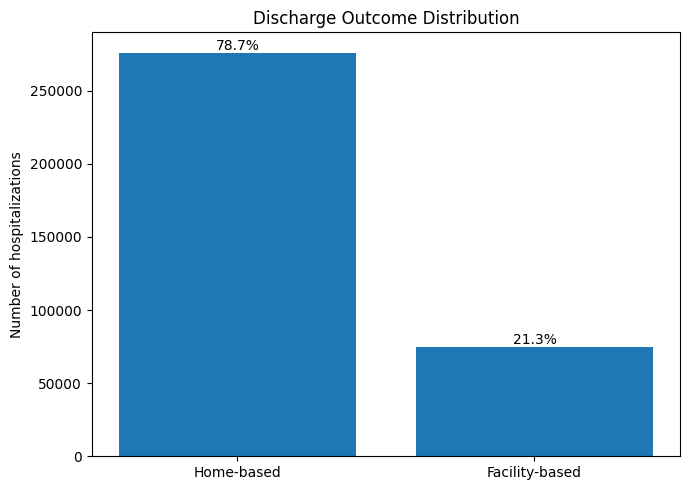

In [20]:
# Distribution of the prediction outcome

outcome_counts = (
    eda_df["discharge_group"].value_counts().reindex(["Home-based", "Facility-based"])
)

outcome_pct = outcome_counts / outcome_counts.sum() * 100

outcome_summary = pd.DataFrame({"Admissions": outcome_counts, "Percent": outcome_pct})

display(outcome_summary.round(1))

plt.figure(figsize=(7, 5))
bars = plt.bar(outcome_counts.index, outcome_counts.values)

plt.ylabel("Number of hospitalizations")
plt.title("Discharge Outcome Distribution")

# Add percentages above bars
for bar, pct in zip(bars, outcome_pct):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{pct:.1f}%",
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.show()


In [21]:
# Age by discharge outcome

age_summary = eda_df.groupby("discharge_group")["age"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

display(age_summary.round(1))


,count,mean,median,std,min,max
discharge_group,,,,,,
Facility-based,74626,72.9,75.0,14.2,18,91
Home-based,276073,57.5,59.0,18.2,18,91


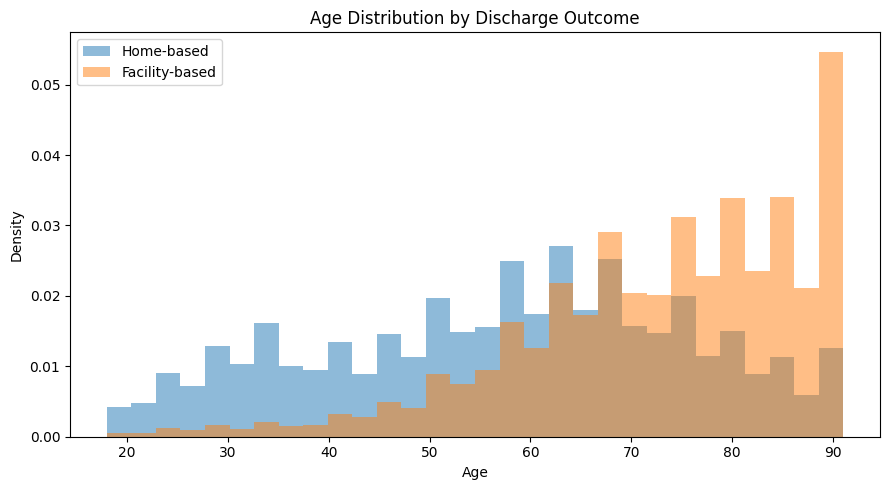

In [22]:
# Age distribution by outcome

plt.figure(figsize=(9, 5))

for group in ["Home-based", "Facility-based"]:
    values = (
        eda_df.loc[eda_df["discharge_group"] == group, "age"].dropna().astype(float)
    )

    plt.hist(values, bins=30, density=True, alpha=0.5, label=group)

plt.xlabel("Age")
plt.ylabel("Density")
plt.title("Age Distribution by Discharge Outcome")
plt.legend()
plt.tight_layout()
plt.show()


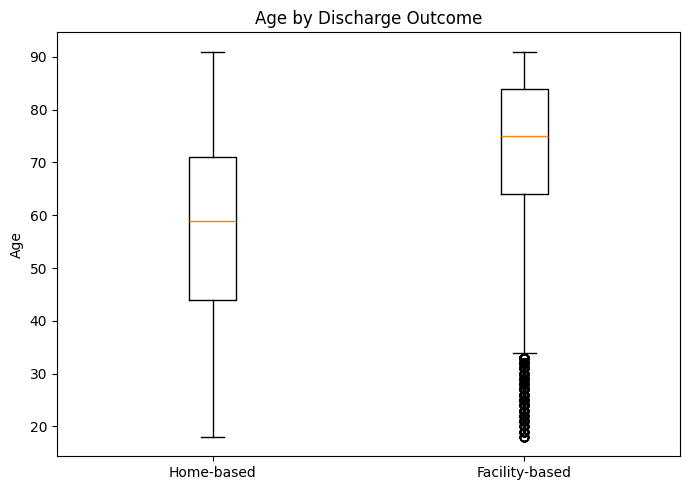

In [23]:
# Age boxplot by outcome

home_age = eda_df.loc[eda_df["facility_discharge"] == 0, "age"].dropna().astype(float)

facility_age = (
    eda_df.loc[eda_df["facility_discharge"] == 1, "age"].dropna().astype(float)
)

plt.figure(figsize=(7, 5))
plt.boxplot([home_age, facility_age], tick_labels=["Home-based", "Facility-based"])

plt.ylabel("Age")
plt.title("Age by Discharge Outcome")
plt.tight_layout()
plt.show()


### Outcome Balance and Age

Facility-based discharge occurs in **21.3% of admissions**, confirming that the positive outcome is less common than home-based discharge.

Age shows a large difference between the two groups. Patients with facility-based discharge have a mean age of **72.9 years** and median age of **75**, compared with a mean age of **57.5** and median age of **59** for home-based discharge.

This suggests that age may be an important predictor of discharge destination. However, the analysis is descriptive: older age may be associated with many other factors relevant to discharge planning, including functional status, comorbidity, social support, and prior living situation, which are not directly measured by age alone.

Patients with de-identified older ages are represented as age 91, so the upper end of the distribution should be interpreted as an older-age group rather than exact age.

In [24]:
# Helper function for categorical predictors
def summarize_categorical_outcome(df, column, top_n=None):
    """
    Summarize the number of admissions and the percentage
    with facility-based discharge for each category.
    """

    temp = df[[column, "facility_discharge"]].copy()

    # Keep missing categorical values visible during EDA
    temp[column] = temp[column].fillna("UNKNOWN").astype(str)

    # Optionally keep only the most common categories
    if top_n is not None:
        common_categories = temp[column].value_counts().head(top_n).index
        temp = temp[temp[column].isin(common_categories)]

    summary = temp.groupby(column)["facility_discharge"].agg(
        admissions="size", facility_rate_pct=lambda x: x.mean() * 100
    )

    return summary.sort_values("facility_rate_pct", ascending=False)


,admissions,facility_rate_pct
sex,,
F,186038,21.5
M,164661,21.1


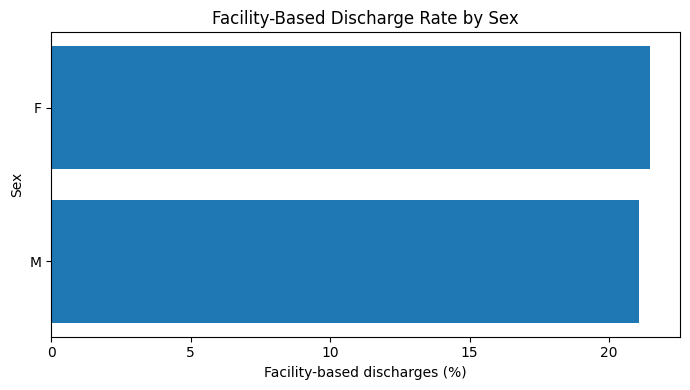

In [25]:
# Plot facility-based discharge (1, positive class) gender distribution

sex_summary = summarize_categorical_outcome(eda_df, "sex")

display(sex_summary.round(1))

plot_data = sex_summary.sort_values("facility_rate_pct")

plt.figure(figsize=(7, 4))
plt.barh(plot_data.index, plot_data["facility_rate_pct"])

plt.xlabel("Facility-based discharges (%)")
plt.ylabel("Sex")
plt.title("Facility-Based Discharge Rate by Sex")
plt.tight_layout()
plt.show()


,admissions,facility_rate_pct
admission_type,,
EW EMER.,150578,25.2
OBSERVATION ADMIT,76264,20.9
URGENT,49347,18.7
SURGICAL SAME DAY ADMISSION,41070,16.5
ELECTIVE,12344,14.9
DIRECT EMER.,19763,14.3
DIRECT OBSERVATION,545,8.8
AMBULATORY OBSERVATION,44,6.8
EU OBSERVATION,744,5.4


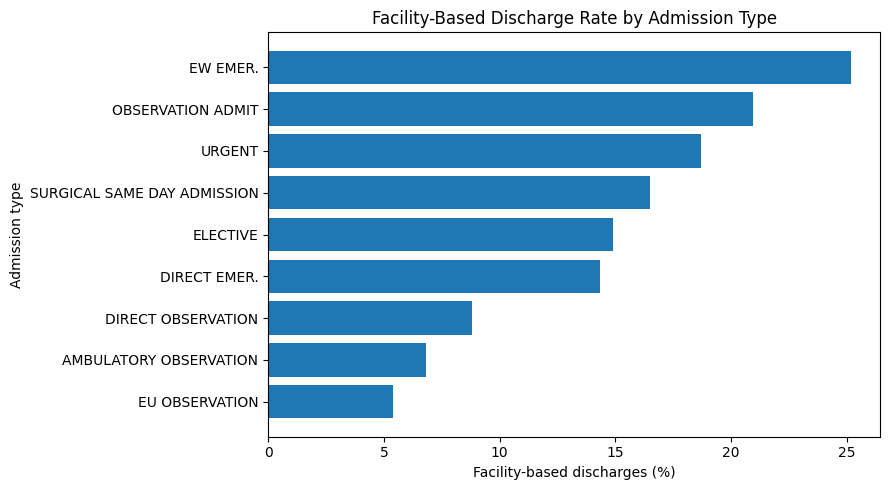

In [26]:
# Plot facility-based discharge percentages by admission type

admission_type_summary = summarize_categorical_outcome(eda_df, "admission_type")

display(admission_type_summary.round(1))

plot_data = admission_type_summary.sort_values("facility_rate_pct")

plt.figure(figsize=(9, 5))
plt.barh(plot_data.index, plot_data["facility_rate_pct"])

plt.xlabel("Facility-based discharges (%)")
plt.ylabel("Admission type")
plt.title("Facility-Based Discharge Rate by Admission Type")
plt.tight_layout()
plt.show()


,admissions,facility_rate_pct
admission_location,,
TRANSFER FROM SKILLED NURSING FACILITY,4191,89.4
INFORMATION NOT AVAILABLE,237,35.0
TRANSFER FROM HOSPITAL,43007,33.3
AMBULATORY SURGERY TRANSFER,184,32.1
EMERGENCY ROOM,137084,25.1
PACU,2022,17.4
CLINIC REFERRAL,9345,15.9
PROCEDURE SITE,3133,13.9
PHYSICIAN REFERRAL,122646,13.6


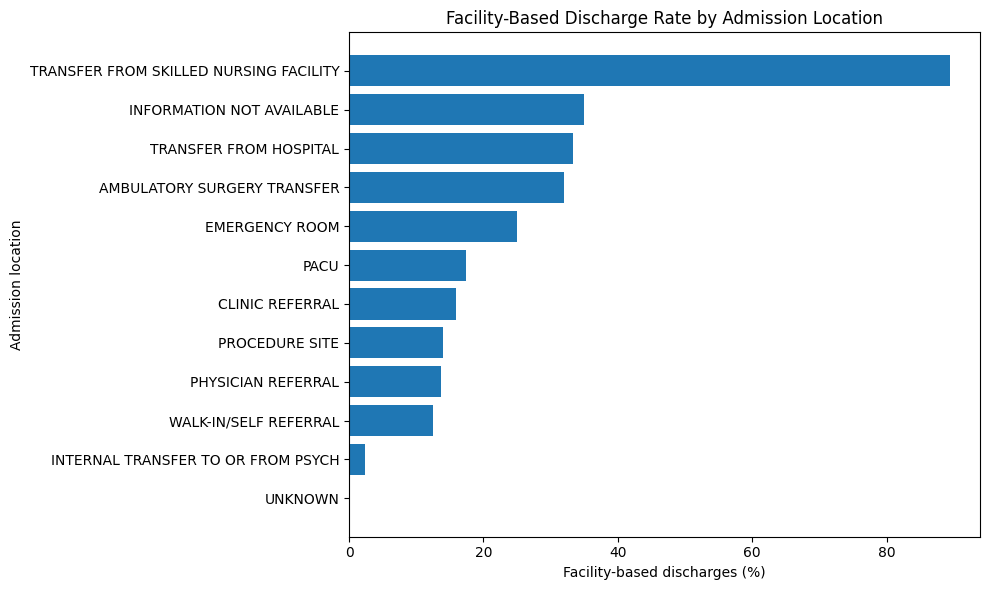

In [27]:
# Plot facility-based discharge percentages by admission location
# Limit the plot to the 12 most common categories for readability.

admission_location_summary = summarize_categorical_outcome(
    eda_df, "admission_location", top_n=12
)

display(admission_location_summary.round(1))

plot_data = admission_location_summary.sort_values("facility_rate_pct")

plt.figure(figsize=(10, 6))
plt.barh(plot_data.index, plot_data["facility_rate_pct"])

plt.xlabel("Facility-based discharges (%)")
plt.ylabel("Admission location")
plt.title("Facility-Based Discharge Rate by Admission Location")
plt.tight_layout()
plt.show()


,admissions,facility_rate_pct
insurance,,
Medicare,168853,33.5
Medicaid,58435,12.9
Other,7977,9.5
Private,111592,8.6
UNKNOWN,3568,5.9
No charge,274,1.1


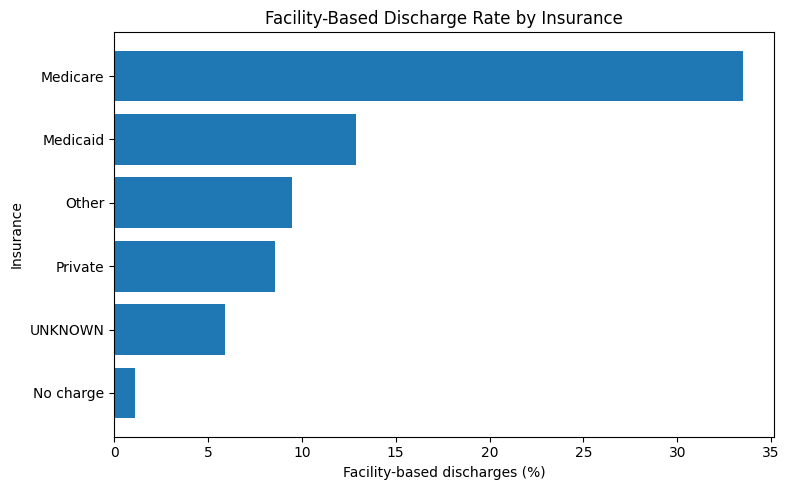

In [28]:
# Plot facility-based discharge percentages by insurance type

insurance_summary = summarize_categorical_outcome(eda_df, "insurance")

display(insurance_summary.round(1))

plot_data = insurance_summary.sort_values("facility_rate_pct")

plt.figure(figsize=(8, 5))
plt.barh(plot_data.index, plot_data["facility_rate_pct"])

plt.xlabel("Facility-based discharges (%)")
plt.ylabel("Insurance")
plt.title("Facility-Based Discharge Rate by Insurance")
plt.tight_layout()
plt.show()


,admissions,facility_rate_pct
marital_status,,
WIDOWED,39245,41.9
UNKNOWN,8878,34.2
DIVORCED,25843,25.5
SINGLE,117194,18.4
MARRIED,159539,16.9


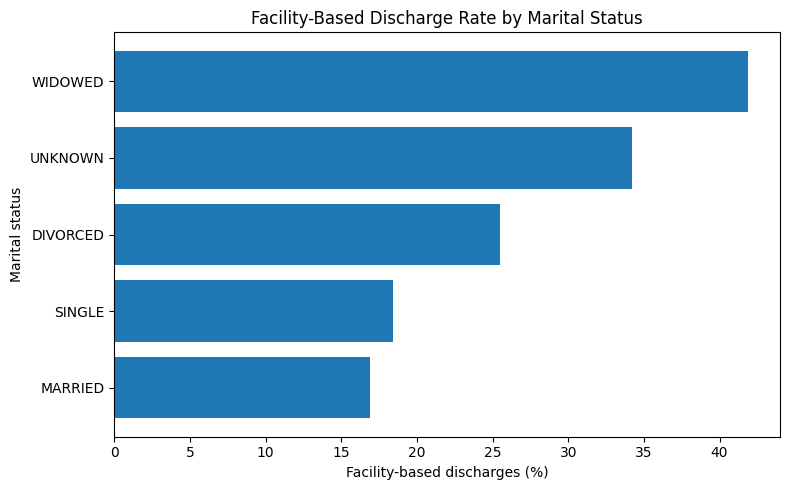

In [29]:
# Plot facility-based discharge percentages by marital status

marital_summary = summarize_categorical_outcome(eda_df, "marital_status")

display(marital_summary.round(1))

plot_data = marital_summary.sort_values("facility_rate_pct")

plt.figure(figsize=(8, 5))
plt.barh(plot_data.index, plot_data["facility_rate_pct"])

plt.xlabel("Facility-based discharges (%)")
plt.ylabel("Marital status")
plt.title("Facility-Based Discharge Rate by Marital Status")
plt.tight_layout()
plt.show()


### Admission Characteristics and Discharge Destination

Several admission-time categorical variables show substantial differences in facility-discharge rates.

**Sex** shows little separation: facility-based discharge occurs in approximately 21% of both female and male admissions.

In contrast, **admission type and admission location** show much larger differences. Emergency admissions have higher facility-discharge rates than elective admissions. The strongest association occurs among patients transferred from a skilled nursing facility: approximately **89.4%** are ultimately discharged to a facility-based setting.

This is clinically plausible because admission location contains information about the patient's pre-hospital setting. It is not data leakage because it is known at admission, but it may act as a strong proxy for prior living arrangement. Therefore, model performance should not be interpreted as being driven only by the patient's first-day physiology.

Insurance and marital status also show substantial unadjusted differences. Medicare admissions and widowed patients have higher facility-discharge rates. These variables are likely related to age and other patient characteristics, so these patterns should be interpreted as associations rather than causal effects.

In [30]:
# Lab availability percentage by discharge outcome

lab_availability = {}

for outcome, label in [(0, "Home-based"), (1, "Facility-based")]:
    subset = eda_df.loc[eda_df["facility_discharge"] == outcome, first_lab_columns]

    # Percent of admissions with an observed measurement
    lab_availability[label] = (1 - subset.isna().mean()) * 100

lab_availability = pd.DataFrame(lab_availability)

# Replace dataframe column names with easier lab names
lab_availability.index = [col.replace("_first", "") for col in lab_availability.index]

lab_availability["Difference"] = (
    lab_availability["Facility-based"] - lab_availability["Home-based"]
)

display(lab_availability.sort_values("Difference", ascending=False).round(1))


,Home-based,Facility-based,Difference
bicarbonate,74.3,88.0,13.7
glucose,73.7,87.2,13.6
bun,74.8,88.2,13.4
sodium,74.5,87.8,13.4
potassium,75.1,88.2,13.1
creatinine,75.8,88.3,12.5
hemoglobin,78.6,87.8,9.2
wbc,78.6,87.8,9.2
platelet,78.7,87.8,9.1


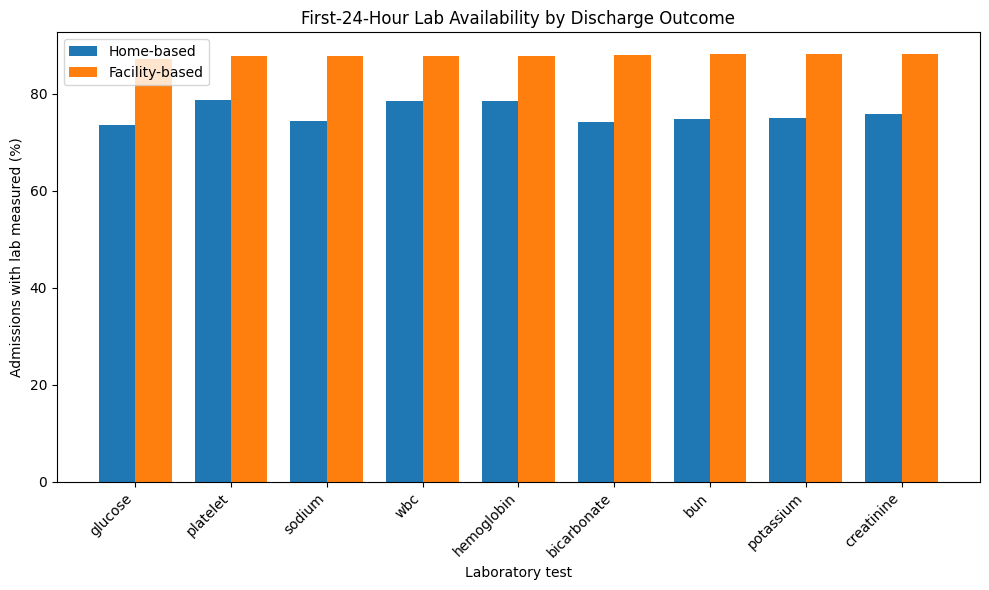

In [31]:
# Plot first 24 hours lab availability by discharge outcome

plot_data = lab_availability[["Home-based", "Facility-based"]].sort_values(
    "Facility-based"
)

plt.figure(figsize=(10, 6))

x = np.arange(len(plot_data))
width = 0.38

plt.bar(x - width / 2, plot_data["Home-based"], width, label="Home-based")

plt.bar(x + width / 2, plot_data["Facility-based"], width, label="Facility-based")

plt.xticks(x, plot_data.index, rotation=45, ha="right")

plt.ylabel("Admissions with lab measured (%)")
plt.xlabel("Laboratory test")
plt.title("First-24-Hour Lab Availability by Discharge Outcome")
plt.legend()
plt.tight_layout()
plt.show()


### Laboratory Availability Differs by Discharge Outcome

Laboratory testing during the first 24 hours is more complete among admissions that ultimately have a facility-based discharge.

For example, bicarbonate is measured in:

- **74.3%** of admissions ending in a home-based discharge,
- **88.0%** of admissions ending in a facility-based discharge,

a difference of **13.7 percentage points**.

Similar differences appear across the other selected laboratory tests. This suggests that laboratory missingness is **not completely random**. Patients who ultimately require facility-based care may have greater clinical complexity or undergo more intensive early evaluation, leading to more frequent laboratory testing.

The primary models use median imputation for missing laboratory values. They do not explicitly use whether a laboratory test was ordered as a predictor, so potentially useful information contained in testing patterns is not directly modeled. Adding missingness indicators would be a reasonable extension for future work.

In [32]:
# Distribution and outlier check for the 36 lab features

lab_distribution_summary = pd.DataFrame(
    {
        "missing_pct": model_df[lab_columns].isna().mean() * 100,
        "min": model_df[lab_columns].min(),
        "p01": model_df[lab_columns].quantile(0.01),
        "median": model_df[lab_columns].median(),
        "mean": model_df[lab_columns].mean(),
        "p99": model_df[lab_columns].quantile(0.99),
        "max": model_df[lab_columns].max(),
    }
)

display(lab_distribution_summary.round(2))


,missing_pct,min,p01,median,mean,p99,max
wbc_first,19.43,0.10,1.50,8.10,9.28,27.10,591.20
wbc_min,19.43,0.10,1.50,7.90,8.90,25.40,591.20
wbc_max,19.43,0.10,1.60,8.30,9.61,28.50,591.20
wbc_mean,19.43,0.10,1.55,8.15,9.25,26.40,591.20
hemoglobin_first,19.42,2.10,6.50,11.10,11.09,15.80,22.00
hemoglobin_min,19.42,2.10,6.30,11.00,10.92,15.60,21.70
hemoglobin_max,19.42,3.00,6.90,11.20,11.20,15.80,22.00
hemoglobin_mean,19.42,3.00,6.80,11.10,11.06,15.70,21.70
platelet_first,19.34,5.00,32.00,214.00,228.72,599.00,2493.00
platelet_min,19.34,5.00,30.00,209.00,223.57,586.00,2493.00


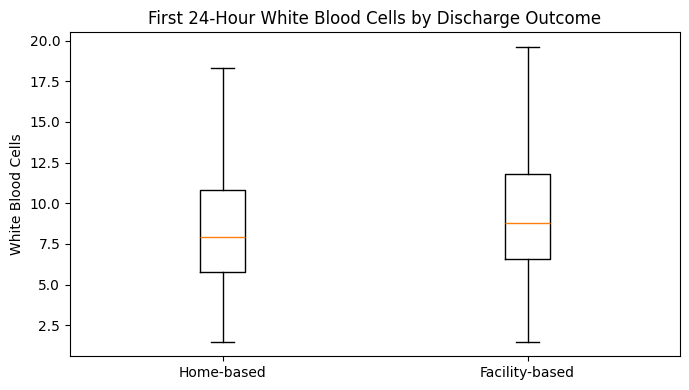

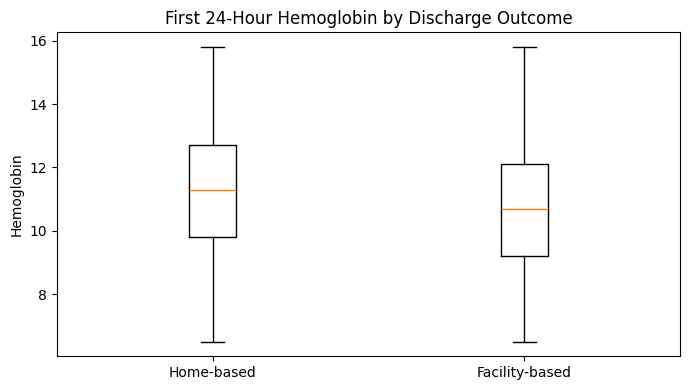

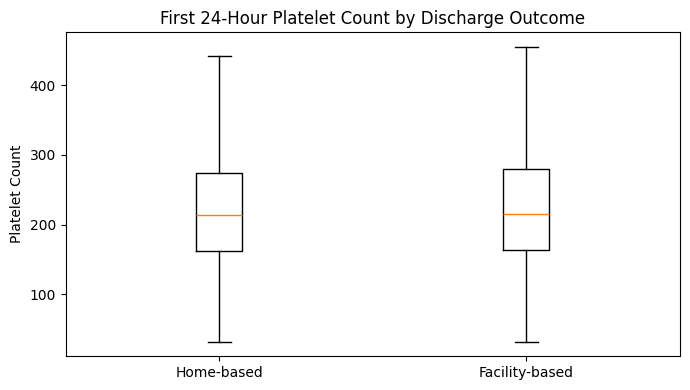

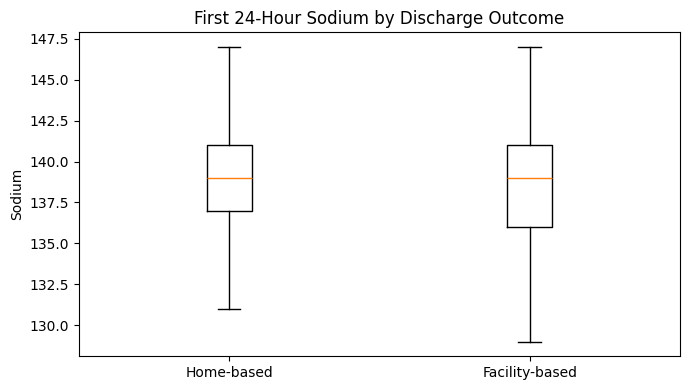

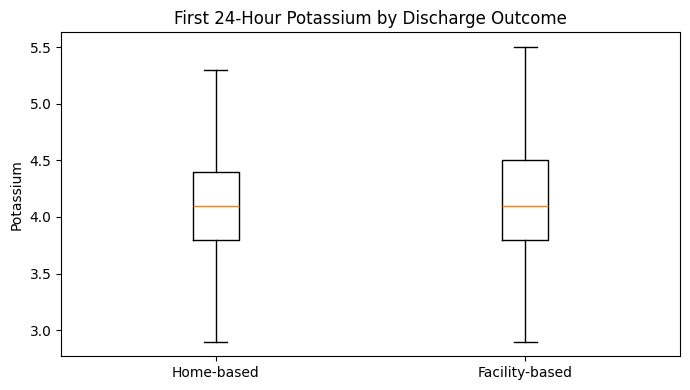

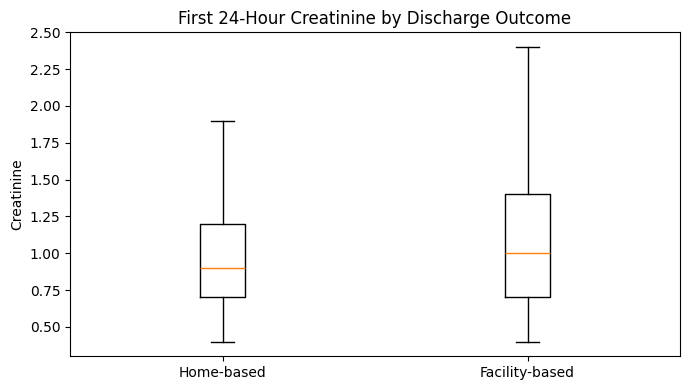

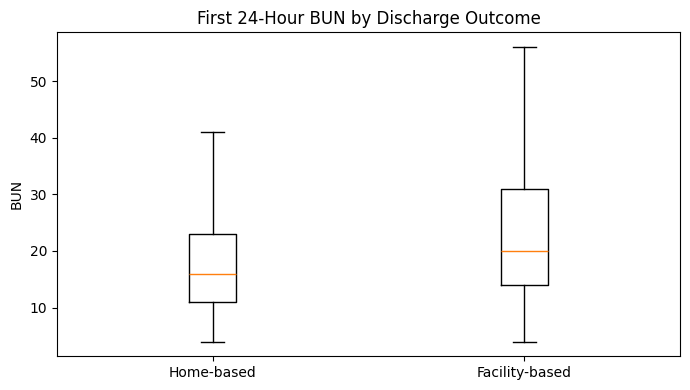

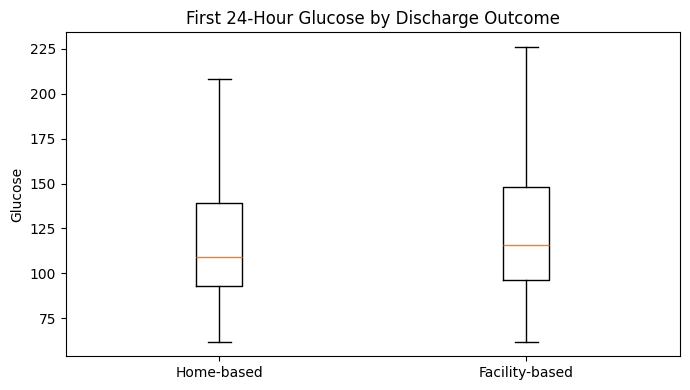

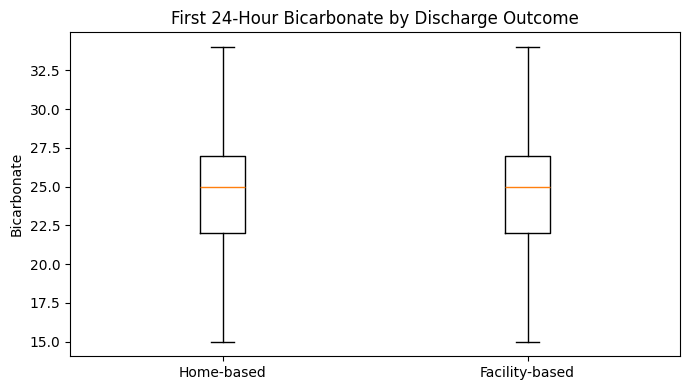

In [33]:
# First lab values by discharge outcome
# Visualization only: clip each plot to its 1st–99th percentiles.
# No values are removed from model_df.

lab_display_names = {
    "wbc_first": "White Blood Cells",
    "hemoglobin_first": "Hemoglobin",
    "platelet_first": "Platelet Count",
    "sodium_first": "Sodium",
    "potassium_first": "Potassium",
    "creatinine_first": "Creatinine",
    "bun_first": "BUN",
    "glucose_first": "Glucose",
    "bicarbonate_first": "Bicarbonate",
}

for column, display_name in lab_display_names.items():

    values = eda_df[column].dropna().astype(float)

    lower = values.quantile(0.01)
    upper = values.quantile(0.99)

    home = (
        eda_df.loc[
            (eda_df["facility_discharge"] == 0)
            & (eda_df[column].between(lower, upper)),
            column,
        ]
        .dropna()
        .astype(float)
    )

    facility = (
        eda_df.loc[
            (eda_df["facility_discharge"] == 1)
            & (eda_df[column].between(lower, upper)),
            column,
        ]
        .dropna()
        .astype(float)
    )

    plt.figure(figsize=(7, 4))

    plt.boxplot(
        [home, facility], tick_labels=["Home-based", "Facility-based"], showfliers=False
    )

    plt.ylabel(display_name)
    plt.title(f"First 24-Hour {display_name} by Discharge Outcome")

    plt.tight_layout()
    plt.show()


In [34]:
# Median first lab value by discharge outcome

lab_group_medians = eda_df.groupby("discharge_group")[first_lab_columns].median().T

lab_group_medians.index = [col.replace("_first", "") for col in lab_group_medians.index]

# Make sure the columns appear in the desired order
lab_group_medians = lab_group_medians[["Home-based", "Facility-based"]]

display(lab_group_medians.round(2))


discharge_group,Home-based,Facility-based
wbc,7.9,8.8
hemoglobin,11.3,10.7
platelet,213.0,215.0
sodium,139.0,139.0
potassium,4.1,4.1
creatinine,0.9,1.0
bun,16.0,21.0
glucose,109.0,116.0
bicarbonate,25.0,25.0


### Laboratory Distributions and Extreme Values

The first laboratory measurements show some differences between outcome groups. Facility-based discharges have higher median first values for several tests, including:

- WBC: **8.8 vs 7.9**
- BUN: **21 vs 16**
- glucose: **116 vs 109**

and slightly lower median hemoglobin:

- **10.7 vs 11.3**

Several variables also contain extreme values far beyond their 99th percentiles. For example, glucose has a 99th percentile in the few-hundred range but contains values above 3,000.

Some extreme measurements may represent true severe physiology, while others may reflect unusual measurements or data-quality issues. Rather than deleting entire admissions, later preprocessing clips each laboratory feature at the **1st and 99th percentiles learned from the training data**. This reduces the influence of extreme observations on scale-sensitive methods while preserving the hospitalization in the dataset.

The clipping shown in the EDA plots is for visualization only; the original modeling dataframe is not modified during EDA.

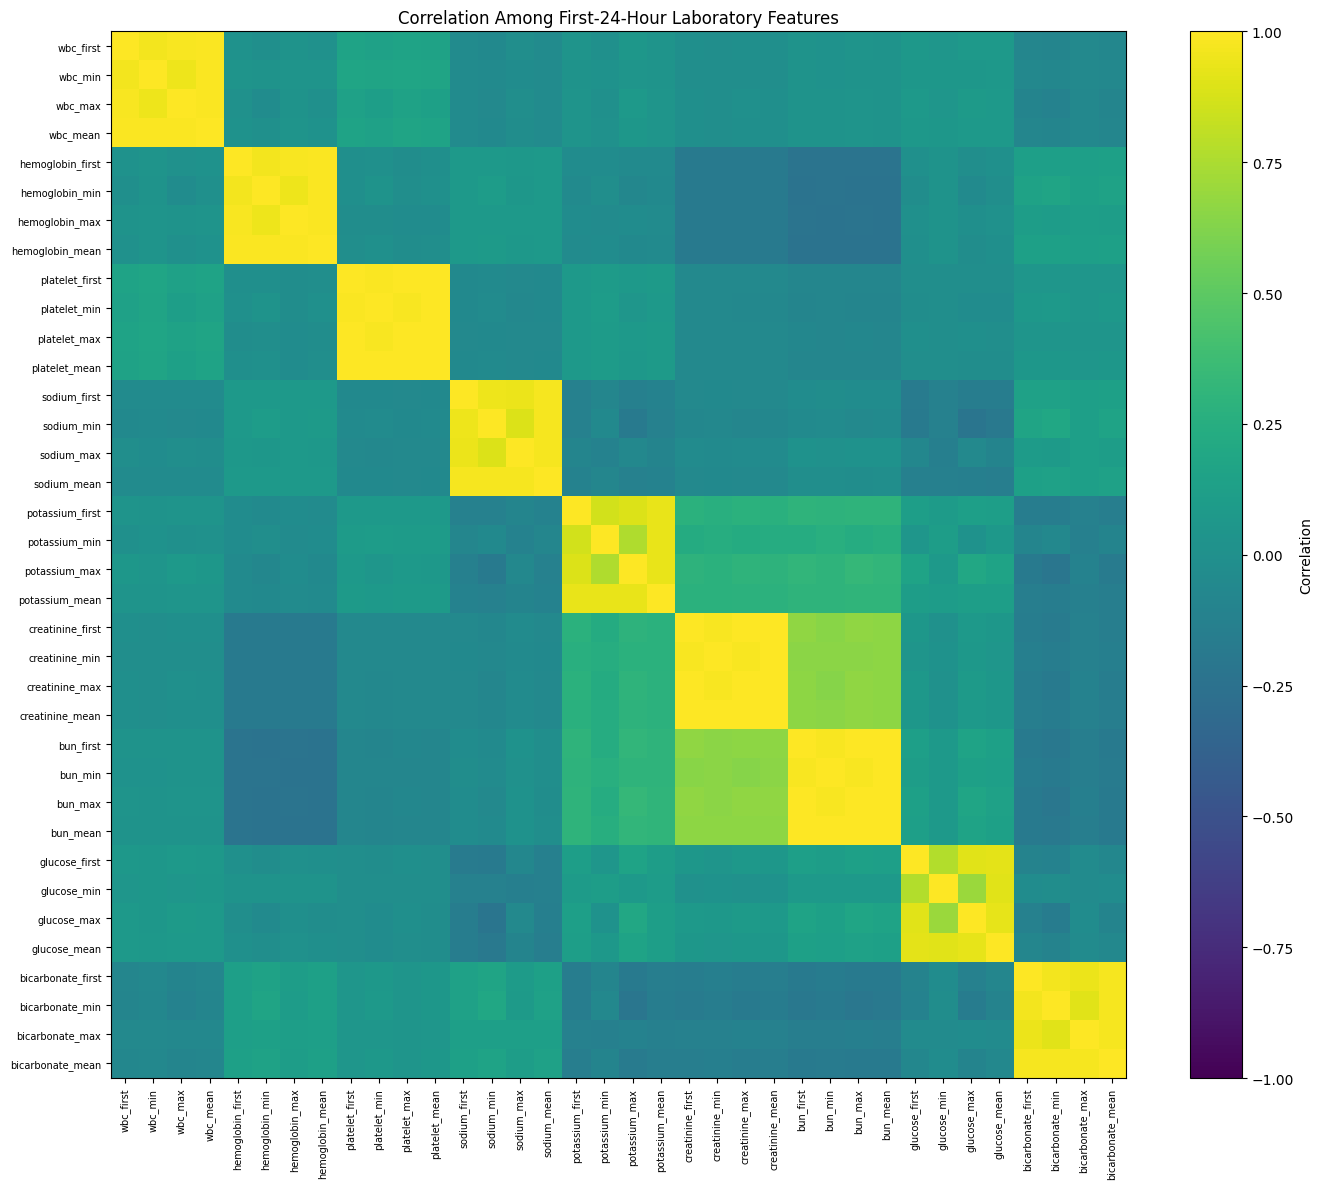

In [35]:
# Correlation among the 36 laboratory features

lab_corr = eda_df[lab_columns].corr()

plt.figure(figsize=(14, 12))

image = plt.imshow(lab_corr, aspect="auto", vmin=-1, vmax=1)

plt.colorbar(image, label="Correlation")

plt.xticks(range(len(lab_columns)), lab_columns, rotation=90, fontsize=7)

plt.yticks(range(len(lab_columns)), lab_columns, fontsize=7)

plt.title("Correlation Among First-24-Hour Laboratory Features")
plt.tight_layout()
plt.show()


In [36]:
# Find the strongest absolute pairwise correlations

upper_triangle = np.triu(np.ones(lab_corr.shape), k=1).astype(bool)

correlation_pairs = lab_corr.where(upper_triangle).stack().reset_index()

correlation_pairs.columns = ["Feature 1", "Feature 2", "Correlation"]

correlation_pairs["Absolute correlation"] = correlation_pairs["Correlation"].abs()

correlation_pairs = correlation_pairs.sort_values(
    "Absolute correlation", ascending=False
)

display(correlation_pairs.head(20).round(3))


,Feature 1,Feature 2,Correlation,Absolute correlation
565,bun_first,bun_max,0.997,0.997
280,platelet_min,platelet_mean,0.996,0.996
585,bun_max,bun_mean,0.995,0.995
305,platelet_max,platelet_mean,0.995,0.995
254,platelet_first,platelet_mean,0.995,0.995
253,platelet_first,platelet_max,0.995,0.995
526,creatinine_min,creatinine_mean,0.995,0.995
512,creatinine_first,creatinine_mean,0.995,0.995
576,bun_min,bun_mean,0.995,0.995
566,bun_first,bun_mean,0.995,0.995


### Correlated Laboratory Features and Motivation for PCA

The four summaries derived from the same laboratory test are highly correlated. Many first/min/max/mean pairs have correlations above **0.98**, and some approach **0.99–1.00**.

This is expected because first, minimum, maximum, and mean measurements from the same 24-hour period often describe closely related information.

The strong correlation motivates testing **Principal Component Analysis (PCA)** as an alternative representation. PCA can combine correlated laboratory variables into a smaller set of components while preserving most of their overall variance.

However, preserving statistical variance does not guarantee preservation of all information useful for predicting discharge destination. Therefore, both the original 36 laboratory features and a PCA-reduced version will be evaluated using the same machine-learning models.

In [37]:
# Missingness and number of categories in admission variables

categorical_summary = pd.DataFrame(
    {
        "missing_count": eda_df[categorical_features].isna().sum(),
        "missing_pct": (eda_df[categorical_features].isna().mean() * 100),
        "unique_categories": [
            eda_df[col].nunique(dropna=True) for col in categorical_features
        ],
    }
)

display(categorical_summary.round(2))


,missing_count,missing_pct,unique_categories
sex,0,0.00,2
admission_type,0,0.00,9
admission_location,1,0.00,11
insurance,3568,1.02,5
marital_status,8878,2.53,4


## Data Preprocessing and Train/Validation/Test Construction

The data are divided at the **patient level**, not randomly by hospitalization. This is important because the same patient may have multiple admissions. If one admission from a patient appeared in training and another appeared in validation or testing, the model could indirectly learn patient-specific patterns and produce an overly optimistic estimate of generalization.

The dataset is therefore divided into three patient-disjoint groups:

- **Subtraining set:** used to fit candidate models and preprocessing transformations.
- **Validation set:** used to compare model configurations and choose the classification threshold.
- **Test set:** held aside until all modeling decisions have been finalized.

The outer split creates an approximately 80% development / 20% test division. The development data are then divided again into subtraining and validation groups.

The resulting partitions contain no overlapping `subject_id` values, and the facility-discharge prevalence remains close to 21% in all three groups. This allows model comparisons without changing the underlying outcome distribution substantially.

In [38]:
# Define the columns and features

# Data preprocessing imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.decomposition import PCA

# Define predictor groups
target_column = "facility_discharge"

identifier_columns = ["subject_id", "hadm_id"]

categorical_features = [
    "sex",
    "admission_type",
    "admission_location",
    "insurance",
    "marital_status",
]

lab_names = [
    "wbc",
    "hemoglobin",
    "platelet",
    "sodium",
    "potassium",
    "creatinine",
    "bun",
    "glucose",
    "bicarbonate",
]

lab_statistics = ["first", "min", "max", "mean"]

# 9 labs × 4 summary statistics = 36 lab features
lab_columns = [f"{lab}_{stat}" for lab in lab_names for stat in lab_statistics]

numerical_features = ["age"] + lab_columns

feature_columns = numerical_features + categorical_features

print("Numerical predictors:", len(numerical_features))
print("Categorical predictors:", len(categorical_features))
print("Total predictors before one-hot encoding:", len(feature_columns))


Numerical predictors: 37
Categorical predictors: 5
Total predictors before one-hot encoding: 42


In [39]:
# Outer patient-group train/test split

# Using 5 folds gives us:
# Approximately 80% development/training data
# Approximately 20% final test data

# subject_id is used as the grouping variable so that
# hospitalizations from the same patient cannot appear
# in both train and test.

outer_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

outer_train_idx, test_idx = next(
    outer_splitter.split(
        model_df, model_df[target_column], groups=model_df["subject_id"]
    )
)

train_df = model_df.iloc[outer_train_idx].copy()

test_df = model_df.iloc[test_idx].copy()

print("Training/development hospitalizations:", len(train_df))

print("Final test hospitalizations:", len(test_df))

print("\nTraining/development patients:", train_df["subject_id"].nunique())

print("Final test patients:", test_df["subject_id"].nunique())


Training/development hospitalizations: 280576
Final test hospitalizations: 70123

Training/development patients: 130728
Final test patients: 32827


In [40]:
# Verify outer split (no patient appears in both datasets)

train_subjects = set(train_df["subject_id"].unique())

test_subjects = set(test_df["subject_id"].unique())

train_test_overlap = train_subjects.intersection(test_subjects)

print("Patients appearing in both train and test:", len(train_test_overlap))

assert len(train_test_overlap) == 0

print("No train/test patient leakage detected.")


Patients appearing in both train and test: 0
No train/test patient leakage detected.


In [41]:
# Inner patient-group split:
# training/development -> subtrain + validation
# All model selection will use:
#   subtrain   -> model fitting
#   validation -> model comparison / threshold selection
# The final test set remains untouched.


inner_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=123)

subtrain_idx, val_idx = next(
    inner_splitter.split(
        train_df, train_df[target_column], groups=train_df["subject_id"]
    )
)

subtrain_df = train_df.iloc[subtrain_idx].copy()

val_df = train_df.iloc[val_idx].copy()

print("Subtraining hospitalizations:", len(subtrain_df))

print("Validation hospitalizations:", len(val_df))

print("Final test hospitalizations:", len(test_df))

print("\nSubtraining patients:", subtrain_df["subject_id"].nunique())

print("Validation patients:", val_df["subject_id"].nunique())

print("Final test patients:", test_df["subject_id"].nunique())


Subtraining hospitalizations: 224349
Validation hospitalizations: 56227
Final test hospitalizations: 70123

Subtraining patients: 104528
Validation patients: 26200
Final test patients: 32827


In [42]:
# Verify no patient appears in more than one split

subtrain_subjects = set(subtrain_df["subject_id"].unique())

val_subjects = set(val_df["subject_id"].unique())

test_subjects = set(test_df["subject_id"].unique())

print(
    "Subtrain / validation overlap:", len(subtrain_subjects.intersection(val_subjects))
)

print("Subtrain / test overlap:", len(subtrain_subjects.intersection(test_subjects)))

print("Validation / test overlap:", len(val_subjects.intersection(test_subjects)))

assert subtrain_subjects.isdisjoint(val_subjects)

assert subtrain_subjects.isdisjoint(test_subjects)

assert val_subjects.isdisjoint(test_subjects)

print("\nAll patient groups are disjoint.")


Subtrain / validation overlap: 0
Subtrain / test overlap: 0
Validation / test overlap: 0

All patient groups are disjoint.


In [43]:
# Check whether stratification preserved outcome balance

split_summary = (
    pd.DataFrame(
        {
            "Subtrain": subtrain_df[target_column].value_counts(normalize=True),
            "Validation": val_df[target_column].value_counts(normalize=True),
            "Test": test_df[target_column].value_counts(normalize=True),
        }
    )
    * 100
)

split_summary.index = ["Home-based", "Facility-based"]

display(split_summary.round(2))


,Subtrain,Validation,Test
Home-based,78.84,78.86,78.22
Facility-based,21.16,21.14,21.78


In [44]:
# Separate predictors (X) and outcome (Y)

X_subtrain = subtrain_df[feature_columns].copy()

X_val = val_df[feature_columns].copy()

# Test predictors are retained but NOT used during
# model selection.
X_test_raw = test_df[feature_columns].copy()

y_subtrain = subtrain_df[target_column].copy()

y_val = val_df[target_column].copy()

y_test = test_df[target_column].copy()

print("X_subtrain:", X_subtrain.shape)

print("X_val:", X_val.shape)

print("X_test_raw:", X_test_raw.shape)


X_subtrain: (224349, 42)
X_val: (56227, 42)
X_test_raw: (70123, 42)


### Rationale behind keeping the Test set separate:

The validation and test sets serve different purposes.

The **validation set** is part of model development. We use it to answer questions such as:

- Which algorithm performs best?
- Do the full laboratory features or PCA features work better?
- What probability threshold provides an appropriate precision/recall tradeoff?

The **test set** is not used to make any of those decisions. It provides a final estimate of performance on patients that played no role in selecting the model.

If we repeatedly compared models and thresholds directly on the test set, our choices would gradually become optimized to that particular sample. Keeping an untouched test set reduces this form of evaluation bias.

In [45]:
# Calculate 1st and 99th percentile lab bounds
# using SUBTRAINING DATA ONLY

lower_bounds = X_subtrain[lab_columns].quantile(0.01)

upper_bounds = X_subtrain[lab_columns].quantile(0.99)

clipping_bounds = pd.DataFrame(
    {"1st percentile": lower_bounds, "99th percentile": upper_bounds}
)

display(clipping_bounds.round(2))


,1st percentile,99th percentile
wbc_first,1.50,27.00
wbc_min,1.50,25.40
wbc_max,1.60,28.40
wbc_mean,1.55,26.40
hemoglobin_first,6.50,15.80
hemoglobin_min,6.40,15.60
hemoglobin_max,7.00,15.80
hemoglobin_mean,6.80,15.70
platelet_first,32.00,598.00
platelet_min,30.00,584.00


In [46]:
# Clip extreme lab values
#
# Bounds learned from subtraining data are applied unchanged
# to validation data.

X_subtrain_clipped = X_subtrain.copy()

X_val_clipped = X_val.copy()

X_subtrain_clipped[lab_columns] = X_subtrain_clipped[lab_columns].clip(
    lower=lower_bounds, upper=upper_bounds, axis=1
)

X_val_clipped[lab_columns] = X_val_clipped[lab_columns].clip(
    lower=lower_bounds, upper=upper_bounds, axis=1
)


In [47]:
# Example difference of maximum glucose value before and after clipping

print("Maximum training glucose before clipping:", X_subtrain["glucose_max"].max())

print(
    "Maximum training glucose after clipping:", X_subtrain_clipped["glucose_max"].max()
)


Maximum training glucose before clipping: 3678.0
Maximum training glucose after clipping: 378.0


In [48]:
# Median imputation for numerical variables
# Medians are learned from subtraining data only.

numeric_imputer = SimpleImputer(strategy="median")

X_subtrain_numeric = pd.DataFrame(
    numeric_imputer.fit_transform(X_subtrain_clipped[numerical_features]),
    columns=numerical_features,
    index=X_subtrain_clipped.index,
)

X_val_numeric = pd.DataFrame(
    numeric_imputer.transform(X_val_clipped[numerical_features]),
    columns=numerical_features,
    index=X_val_clipped.index,
)

print("Missing subtraining numerical values:", X_subtrain_numeric.isna().sum().sum())

print("Missing validation numerical values:", X_val_numeric.isna().sum().sum())


Missing subtraining numerical values: 0
Missing validation numerical values: 0


In [49]:
# Show the medians that missing values are imputed to

imputation_values = pd.Series(
    numeric_imputer.statistics_, index=numerical_features, name="training_median"
)

display(imputation_values.round(2))


,training_median
age,63.0
wbc_first,8.1
wbc_min,7.9
wbc_max,8.3
wbc_mean,8.1
hemoglobin_first,11.2
hemoglobin_min,11.0
hemoglobin_max,11.2
hemoglobin_mean,11.1
platelet_first,213.0


In [50]:
# Replace missing categorical values with UNKNOWN

categorical_imputer = SimpleImputer(strategy="constant", fill_value="UNKNOWN")

subtrain_cat_input = (
    X_subtrain_clipped[categorical_features].astype("object").replace({pd.NA: np.nan})
)

val_cat_input = (
    X_val_clipped[categorical_features].astype("object").replace({pd.NA: np.nan})
)

X_subtrain_categorical = pd.DataFrame(
    categorical_imputer.fit_transform(subtrain_cat_input),
    columns=categorical_features,
    index=X_subtrain_clipped.index,
)

X_val_categorical = pd.DataFrame(
    categorical_imputer.transform(val_cat_input),
    columns=categorical_features,
    index=X_val_clipped.index,
)

print(
    "Missing subtraining categorical values:", X_subtrain_categorical.isna().sum().sum()
)

print("Missing validation categorical values:", X_val_categorical.isna().sum().sum())


Missing subtraining categorical values: 0
Missing validation categorical values: 0


In [51]:
# One-hot encode categorical predictors
# Encoder is fitted on subtraining data only.

onehot_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

X_subtrain_encoded_array = onehot_encoder.fit_transform(X_subtrain_categorical)

X_val_encoded_array = onehot_encoder.transform(X_val_categorical)

encoded_feature_names = onehot_encoder.get_feature_names_out(categorical_features)

X_subtrain_categorical_encoded = pd.DataFrame(
    X_subtrain_encoded_array, columns=encoded_feature_names, index=X_subtrain.index
)

X_val_categorical_encoded = pd.DataFrame(
    X_val_encoded_array, columns=encoded_feature_names, index=X_val.index
)

print("Categorical variables before encoding:", len(categorical_features))

print("Columns after one-hot encoding:", len(encoded_feature_names))


Categorical variables before encoding: 5
Columns after one-hot encoding: 33


In [52]:
# Show the categorical columns after one-hot encoding

display(X_subtrain_categorical_encoded.head())


,sex_F,sex_M,admission_type_AMBULATORY OBSERVATION,admission_type_DIRECT EMER.,admission_type_DIRECT OBSERVATION,admission_type_ELECTIVE,admission_type_EU OBSERVATION,admission_type_EW EMER.,admission_type_OBSERVATION ADMIT,admission_type_SURGICAL SAME DAY ADMISSION,...,insurance_Medicare,insurance_No charge,insurance_Other,insurance_Private,insurance_UNKNOWN,marital_status_DIVORCED,marital_status_MARRIED,marital_status_SINGLE,marital_status_UNKNOWN,marital_status_WIDOWED
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
9,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


In [53]:
# Standardize numerical predictors
# Mean and standard deviation are learned from
# subtraining data only.

scaler = StandardScaler()

X_subtrain_numeric_scaled = pd.DataFrame(
    scaler.fit_transform(X_subtrain_numeric),
    columns=numerical_features,
    index=X_subtrain_numeric.index,
)

X_val_numeric_scaled = pd.DataFrame(
    scaler.transform(X_val_numeric),
    columns=numerical_features,
    index=X_val_numeric.index,
)

display(
    X_subtrain_numeric_scaled[["age", "wbc_first", "creatinine_first", "glucose_first"]]
    .describe()
    .round(2)
)


,age,wbc_first,creatinine_first,glucose_first
count,224349.00,224349.00,224349.00,224349.00
mean,-0.00,-0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00
min,-2.32,-1.77,-0.69,-1.32
25%,-0.69,-0.57,-0.36,-0.52
50%,0.12,-0.18,-0.27,-0.27
75%,0.77,0.33,-0.10,0.14
max,1.64,4.39,6.39,4.99


In [54]:
# Full feature representation:
# 37 standardized numerical predictors
# and one-hot encoded categorical predictors

X_subtrain_full = pd.concat(
    [X_subtrain_numeric_scaled, X_subtrain_categorical_encoded], axis=1
)

X_val_full = pd.concat([X_val_numeric_scaled, X_val_categorical_encoded], axis=1)

print("Full subtraining matrix:", X_subtrain_full.shape)

print("Full validation matrix:", X_val_full.shape)


Full subtraining matrix: (224349, 70)
Full validation matrix: (56227, 70)


### Preprocessing the Predictors

All preprocessing parameters are learned from the **subtraining set only** and then applied unchanged to validation data. This prevents information from the validation set from influencing model preparation.

The preprocessing steps are:

**Outlier clipping:** Laboratory values are clipped to the 1st and 99th percentile limits calculated from subtraining data. For example, the maximum glucose value decreases from 3,678 to the training-derived 99th-percentile limit of 378.

**Numerical imputation:** Missing numerical values are replaced with the median calculated from subtraining data. This preserves admissions with incomplete laboratory testing while using a robust central value.

**Categorical missing values:** Missing categorical values are represented as `UNKNOWN` rather than assuming they belong to the most common category.

**One-hot encoding:** The five categorical predictors are expanded into binary indicator variables. This allows the machine-learning algorithms to use categorical information without assigning an artificial numerical order to categories.

**Standardization:** Numerical predictors are transformed to approximately mean 0 and standard deviation 1. Standardization is important for Logistic Regression and especially PCA because those methods are sensitive to feature scale. Random Forest and XGBoost do not require scaling, but the same processed representation is used across models to keep the comparisons consistent.

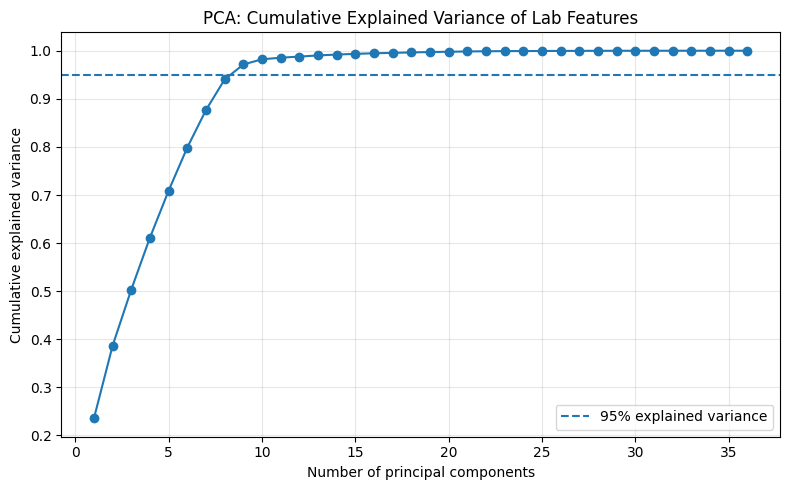

In [55]:
# PCA exploration using the 36 standardized lab variables
# PCA is fitted ONLY on subtraining data.

pca_all = PCA()

pca_all.fit(X_subtrain_numeric_scaled[lab_columns])

cumulative_variance = np.cumsum(pca_all.explained_variance_ratio_)

plt.figure(figsize=(8, 5))

plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker="o")

plt.axhline(y=0.95, linestyle="--", label="95% explained variance")

plt.xlabel("Number of principal components")

plt.ylabel("Cumulative explained variance")

plt.title("PCA: Cumulative Explained Variance of Lab Features")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [56]:
# Find the smallest number of PCs explaining at least 95% of the variance

n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1

print("Principal components required for 95% explained variance:", n_components_95)

print("Original lab features:", len(lab_columns))


Principal components required for 95% explained variance: 9
Original lab features: 36


In [57]:
# Fit final PCA on subtraining labs
# and apply unchanged to validation labs

pca = PCA(n_components=n_components_95)

X_subtrain_lab_pca_array = pca.fit_transform(X_subtrain_numeric_scaled[lab_columns])

X_val_lab_pca_array = pca.transform(X_val_numeric_scaled[lab_columns])

pca_feature_names = [f"lab_PC{i+1}" for i in range(n_components_95)]

X_subtrain_lab_pca = pd.DataFrame(
    X_subtrain_lab_pca_array, columns=pca_feature_names, index=X_subtrain.index
)

X_val_lab_pca = pd.DataFrame(
    X_val_lab_pca_array, columns=pca_feature_names, index=X_val.index
)

print("Lab dimensions before PCA:", len(lab_columns))

print("Lab dimensions after PCA:", n_components_95)


Lab dimensions before PCA: 36
Lab dimensions after PCA: 9


In [58]:
# PCA feature representation
# Age remains a separate predictor
# Only the 36 laboratory variables are replaced by PCs

X_subtrain_pca = pd.concat(
    [
        X_subtrain_numeric_scaled[["age"]],
        X_subtrain_lab_pca,
        X_subtrain_categorical_encoded,
    ],
    axis=1,
)

X_val_pca = pd.concat(
    [X_val_numeric_scaled[["age"]], X_val_lab_pca, X_val_categorical_encoded], axis=1
)

print("Full feature representation:")

print("  Subtrain:", X_subtrain_full.shape)

print("  Validation:", X_val_full.shape)

print("\nPCA feature representation:")

print("  Subtrain:", X_subtrain_pca.shape)

print("  Validation:", X_val_pca.shape)


Full feature representation:
  Subtrain: (224349, 70)
  Validation: (56227, 70)

PCA feature representation:
  Subtrain: (224349, 43)
  Validation: (56227, 43)


### Principal Component Analysis

PCA is applied **only to the 36 laboratory variables**. Age and the categorical admission variables remain separate because they have direct meanings that we want to preserve.

After standardization, only **9 principal components** are required to retain at least **95% of the variance** contained in the original 36 laboratory features.

This creates two parallel model inputs:

- **Full representation:** 70 predictors after numerical and categorical preprocessing.
- **PCA representation:** 43 predictors, where the 36 laboratory features are replaced by 9 principal components.

The purpose of this comparison is not to assume that PCA is better, but to test whether a substantially smaller laboratory representation can retain comparable predictive performance.

In [59]:
# Final validation of model-development matrices

print("Missing values:")

print("X_subtrain_full:", X_subtrain_full.isna().sum().sum())

print("X_val_full:", X_val_full.isna().sum().sum())

print("X_subtrain_pca:", X_subtrain_pca.isna().sum().sum())

print("X_val_pca:", X_val_pca.isna().sum().sum())

print("\nFeature dimensions:")

print("Original lab features:", len(lab_columns))

print("PCA lab features:", n_components_95)

print("Total full-model predictors:", X_subtrain_full.shape[1])

print("Total PCA-model predictors:", X_subtrain_pca.shape[1])

assert X_subtrain_full.isna().sum().sum() == 0

assert X_val_full.isna().sum().sum() == 0

assert X_subtrain_pca.isna().sum().sum() == 0

assert X_val_pca.isna().sum().sum() == 0

assert subtrain_subjects.isdisjoint(val_subjects)

assert subtrain_subjects.isdisjoint(test_subjects)

assert val_subjects.isdisjoint(test_subjects)

print("\nAll preprocessing checks passed.")

print("Final test set has not been used for model selection.")


Missing values:
X_subtrain_full: 0
X_val_full: 0
X_subtrain_pca: 0
X_val_pca: 0

Feature dimensions:
Original lab features: 36
PCA lab features: 9
Total full-model predictors: 70
Total PCA-model predictors: 43

All preprocessing checks passed.
Final test set has not been used for model selection.


### Model-Ready Feature Sets

At this point, we have two parallel feature representations ready for modeling:

1. **Full representation (`X_subtrain_full` / `X_val_full`)**  
   Contains **70 predictors** after preprocessing: standardized age, the original 36 laboratory features, and one-hot encoded admission variables.

2. **PCA representation (`X_subtrain_pca` / `X_val_pca`)**  
   Contains **43 predictors**: standardized age, 9 principal components replacing the 36 laboratory features, and the same one-hot encoded admission variables.

Using identical subtraining and validation patients allows us to compare whether PCA's dimensionality reduction improves, preserves, or reduces predictive performance.

In [60]:
# Model evaluation setup

import time

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)

model_results = []


In [61]:
# Helper function to fit on subtraining data
# and evaluate on validation data


def evaluate_model(
    model, model_name, feature_set, X_train_data, X_val_data, y_train_data, y_val_data
):
    """
    Fit a binary classifier on the subtraining set and
    evaluate it on the held-out validation set.

    Positive class (1):
        Facility-based discharge

    Negative class (0):
        Home-based discharge
    """

    start_time = time.time()

    # Train model
    model.fit(X_train_data, y_train_data)

    training_time = time.time() - start_time

    # Probability of facility-based discharge
    y_prob = model.predict_proba(X_val_data)[:, 1]

    # Baseline classification threshold
    y_pred = (y_prob >= 0.50).astype(int)

    results = {
        "Model": model_name,
        "Features": feature_set,
        "Accuracy": accuracy_score(y_val_data, y_pred),
        "Precision": precision_score(y_val_data, y_pred, zero_division=0),
        "Recall": recall_score(y_val_data, y_pred),
        "F1": f1_score(y_val_data, y_pred),
        "ROC-AUC": roc_auc_score(y_val_data, y_prob),
        "PR-AUC": average_precision_score(y_val_data, y_prob),
        "Training Time (sec)": training_time,
    }

    model_results.append(results)

    print(f"{model_name} — {feature_set}")

    print("-" * 55)

    print(
        classification_report(
            y_val_data, y_pred, target_names=["Home-based", "Facility-based"]
        )
    )

    print(f"ROC-AUC: " f"{results['ROC-AUC']:.3f}")

    print(f"PR-AUC : " f"{results['PR-AUC']:.3f}")

    print(f"Training time: " f"{training_time:.1f} seconds")

    # Confusion matrix
    cm = confusion_matrix(y_val_data, y_pred)

    plt.figure(figsize=(5, 4))

    plt.imshow(cm, cmap="PuBuGn_r")

    plt.xticks([0, 1], ["Home-based", "Facility-based"])

    plt.yticks([0, 1], ["Home-based", "Facility-based"])

    plt.xlabel("Predicted")

    plt.ylabel("Actual")

    plt.title(f"{model_name} — {feature_set}\n" "Validation Confusion Matrix")

    for i in range(2):
        for j in range(2):
            plt.text(j, i, f"{cm[i, j]:,}", ha="center", va="center")

    plt.tight_layout()
    plt.show()

    return (model, y_prob, y_pred)


## Logistic Regression

Logistic Regression provides a useful baseline because it models the probability of facility-based discharge as a linear combination of the predictors.

It is relatively interpretable and allows us to examine the direction and magnitude of model coefficients. Because the numerical variables have been standardized, their coefficients are placed on a more comparable scale.

We train two Logistic Regression models:

1. using the **full laboratory feature set**, and
2. using the **PCA-reduced laboratory representation**.

Both models are trained on the subtraining set and evaluated on the same validation patients using a default probability threshold of 0.50.


Logistic Regression — Full
-------------------------------------------------------
                precision    recall  f1-score   support

    Home-based       0.83      0.96      0.89     44338
Facility-based       0.63      0.26      0.37     11889

      accuracy                           0.81     56227
     macro avg       0.73      0.61      0.63     56227
  weighted avg       0.79      0.81      0.78     56227

ROC-AUC: 0.802
PR-AUC : 0.531
Training time: 14.6 seconds


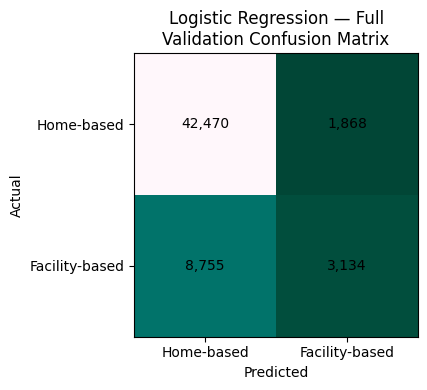

In [62]:
# Logistic Regression — full feature representation

from sklearn.linear_model import LogisticRegression

logreg_full = LogisticRegression(max_iter=1000, solver="lbfgs", random_state=42)

(logreg_full, logreg_full_prob, logreg_full_pred) = evaluate_model(
    model=logreg_full,
    model_name="Logistic Regression",
    feature_set="Full",
    X_train_data=X_subtrain_full,
    X_val_data=X_val_full,
    y_train_data=y_subtrain,
    y_val_data=y_val,
)


Logistic Regression — PCA
-------------------------------------------------------
                precision    recall  f1-score   support

    Home-based       0.83      0.96      0.89     44338
Facility-based       0.62      0.25      0.36     11889

      accuracy                           0.81     56227
     macro avg       0.72      0.61      0.62     56227
  weighted avg       0.78      0.81      0.78     56227

ROC-AUC: 0.799
PR-AUC : 0.524
Training time: 12.1 seconds


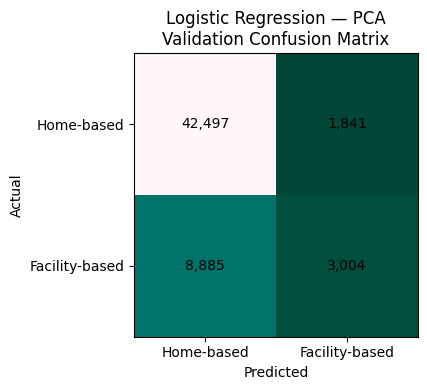

In [63]:
# Logistic Regression — PCA feature representation

logreg_pca = LogisticRegression(max_iter=1000, solver="lbfgs", random_state=42)

(logreg_pca, logreg_pca_prob, logreg_pca_pred) = evaluate_model(
    model=logreg_pca,
    model_name="Logistic Regression",
    feature_set="PCA",
    X_train_data=X_subtrain_pca,
    X_val_data=X_val_pca,
    y_train_data=y_subtrain,
    y_val_data=y_val,
)


### Logistic Regression Results

The full Logistic Regression model performs slightly better than the PCA version:

- Full: **ROC-AUC 0.802, PR-AUC 0.531**
- PCA: **ROC-AUC 0.799, PR-AUC 0.524**

The difference is small, suggesting that PCA retains much of the predictive information available to a linear classifier. However, the original laboratory representation still performs slightly better.

At the default 0.50 classification threshold, both versions have relatively high precision but low recall for facility-based discharge. The full model identifies only about **26%** of actual facility-based discharges. This suggests that the probability ranking may contain useful information even though the default threshold is too conservative for a screening-oriented application.

The Logistic Regression coefficients identify strong associations with variables such as age and admission location. These coefficients should be interpreted as predictive associations, not causal effects.

In [64]:
# Logistic Regression coefficients — full model

logreg_coefficients = pd.DataFrame(
    {"feature": X_subtrain_full.columns, "coefficient": logreg_full.coef_[0]}
)

logreg_coefficients["absolute_coefficient"] = logreg_coefficients["coefficient"].abs()

logreg_coefficients = logreg_coefficients.sort_values(
    "absolute_coefficient", ascending=False
)

display(logreg_coefficients.head(20))


,feature,coefficient,absolute_coefficient
57,admission_location_TRANSFER FROM SKILLED NURSI...,2.872430,2.872430
52,admission_location_INTERNAL TRANSFER TO OR FRO...,-1.740023,1.740023
43,admission_type_EU OBSERVATION,-1.002320,1.002320
55,admission_location_PROCEDURE SITE,-0.862817,0.862817
0,age,0.861696,0.861696
58,admission_location_WALK-IN/SELF REFERRAL,-0.836968,0.836968
21,creatinine_first,-0.747057,0.747057
64,insurance_UNKNOWN,-0.705877,0.705877
66,marital_status_MARRIED,-0.686487,0.686487
54,admission_location_PHYSICIAN REFERRAL,-0.593653,0.593653


## Random Forest

Random Forest is an ensemble of many decision trees. Each tree learns nonlinear decision rules, and the final classification is based on the combined predictions of the trees.

Unlike Logistic Regression, Random Forest can naturally model nonlinear relationships and interactions between variables. It also does not require variables to have a linear relationship with the outcome.

As with Logistic Regression, we compare a model using all original laboratory features with one using PCA-reduced laboratory features.

Random Forest — Full
-------------------------------------------------------
                precision    recall  f1-score   support

    Home-based       0.83      0.96      0.89     44338
Facility-based       0.63      0.27      0.38     11889

      accuracy                           0.81     56227
     macro avg       0.73      0.61      0.63     56227
  weighted avg       0.79      0.81      0.78     56227

ROC-AUC: 0.795
PR-AUC : 0.515
Training time: 172.8 seconds


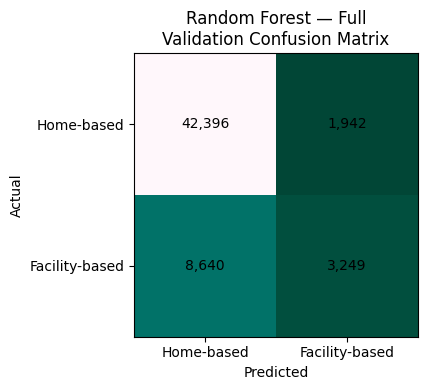

In [65]:
# Random Forest — full feature representation

from sklearn.ensemble import RandomForestClassifier

rf_full = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)

(rf_full, rf_full_prob, rf_full_pred) = evaluate_model(
    model=rf_full,
    model_name="Random Forest",
    feature_set="Full",
    X_train_data=X_subtrain_full,
    X_val_data=X_val_full,
    y_train_data=y_subtrain,
    y_val_data=y_val,
)


Random Forest — PCA
-------------------------------------------------------
                precision    recall  f1-score   support

    Home-based       0.83      0.95      0.89     44338
Facility-based       0.61      0.27      0.37     11889

      accuracy                           0.81     56227
     macro avg       0.72      0.61      0.63     56227
  weighted avg       0.78      0.81      0.78     56227

ROC-AUC: 0.792
PR-AUC : 0.510
Training time: 171.7 seconds


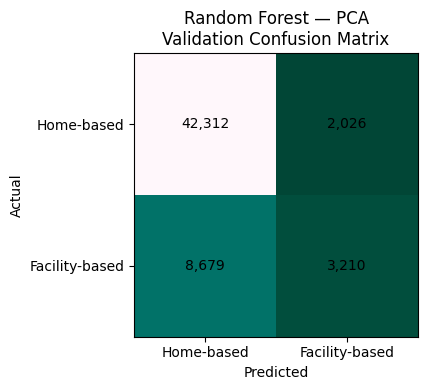

In [66]:
# Random Forest — PCA feature representation

rf_pca = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)

(rf_pca, rf_pca_prob, rf_pca_pred) = evaluate_model(
    model=rf_pca,
    model_name="Random Forest",
    feature_set="PCA",
    X_train_data=X_subtrain_pca,
    X_val_data=X_val_pca,
    y_train_data=y_subtrain,
    y_val_data=y_val,
)


### Random Forest Results

Random Forest again performs slightly better using the full feature representation:

- Full: **ROC-AUC 0.795, PR-AUC 0.515**
- PCA: **ROC-AUC 0.792, PR-AUC 0.510**

The difference is small but consistent with the Logistic Regression result: reducing the laboratory measurements to principal components does not improve predictive performance.

At the default threshold, recall remains low at approximately **27%**, even though precision is above 60%. The model therefore makes relatively few facility predictions and misses many patients who ultimately have a facility-based discharge.

Age has the highest Random Forest feature importance, while numerous laboratory summaries contribute smaller amounts. Random Forest feature importance measures usefulness for prediction within the model and should not be interpreted as evidence that a variable causes the discharge outcome.

In [67]:
# Random Forest feature importance — full model

rf_importance = pd.DataFrame(
    {"feature": X_subtrain_full.columns, "importance": rf_full.feature_importances_}
)

rf_importance = rf_importance.sort_values("importance", ascending=False)

display(rf_importance.head(20))


,feature,importance
0,age,0.107650
60,insurance_Medicare,0.028354
3,wbc_max,0.026579
4,wbc_mean,0.026461
1,wbc_first,0.024804
2,wbc_min,0.024290
6,hemoglobin_min,0.023999
31,glucose_max,0.023944
32,glucose_mean,0.023647
10,platelet_min,0.023637


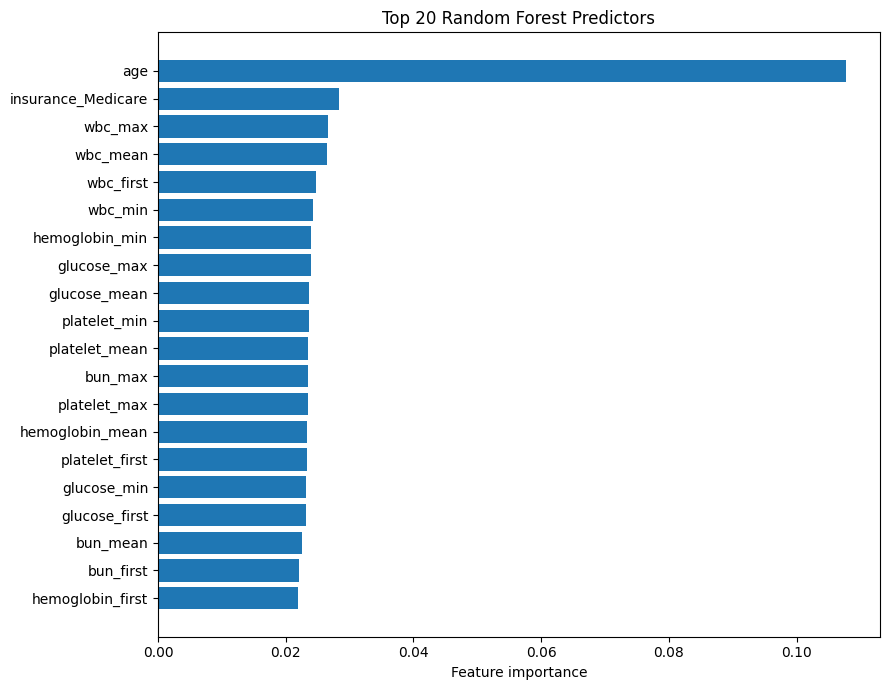

In [68]:
# Plot top 20 Random Forest predictors

top_features = rf_importance.head(20).sort_values("importance")

plt.figure(figsize=(9, 7))

plt.barh(top_features["feature"], top_features["importance"])

plt.xlabel("Feature importance")
plt.title("Top 20 Random Forest Predictors")
plt.tight_layout()
plt.show()


## XGBoost Classifier

XGBoost is a gradient-boosted tree algorithm. Unlike Random Forest, which builds many relatively independent trees and averages them, boosting builds trees sequentially so that later trees focus on correcting errors made by earlier trees.

This allows XGBoost to model nonlinear relationships and interactions while often achieving strong predictive performance on structured tabular data.

The same full-versus-PCA comparison is repeated so that differences can be attributed to the feature representation rather than to different evaluation procedures.

XGBoost — Full
-------------------------------------------------------
                precision    recall  f1-score   support

    Home-based       0.83      0.96      0.89     44338
Facility-based       0.65      0.28      0.40     11889

      accuracy                           0.82     56227
     macro avg       0.74      0.62      0.64     56227
  weighted avg       0.80      0.82      0.79     56227

ROC-AUC: 0.814
PR-AUC : 0.556
Training time: 26.3 seconds


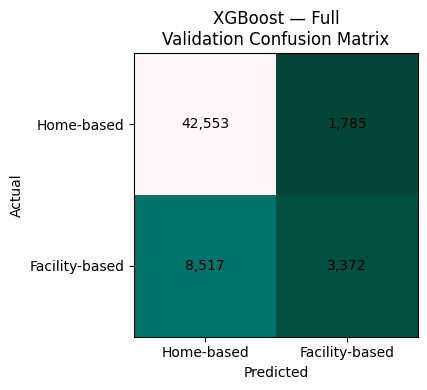

In [69]:
# XGBoost — full feature representation

from xgboost import XGBClassifier

xgb_full = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
)

(xgb_full, xgb_full_prob, xgb_full_pred) = evaluate_model(
    model=xgb_full,
    model_name="XGBoost",
    feature_set="Full",
    X_train_data=X_subtrain_full,
    X_val_data=X_val_full,
    y_train_data=y_subtrain,
    y_val_data=y_val,
)


XGBoost — PCA
-------------------------------------------------------
                precision    recall  f1-score   support

    Home-based       0.83      0.96      0.89     44338
Facility-based       0.64      0.27      0.38     11889

      accuracy                           0.81     56227
     macro avg       0.74      0.61      0.63     56227
  weighted avg       0.79      0.81      0.78     56227

ROC-AUC: 0.809
PR-AUC : 0.543
Training time: 16.8 seconds


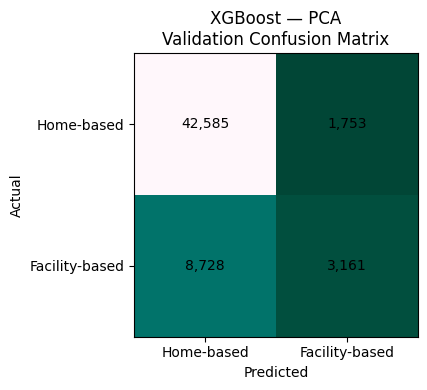

In [70]:
# XGBoost — PCA feature representation

xgb_pca = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
)

(xgb_pca, xgb_pca_prob, xgb_pca_pred) = evaluate_model(
    model=xgb_pca,
    model_name="XGBoost",
    feature_set="PCA",
    X_train_data=X_subtrain_pca,
    X_val_data=X_val_pca,
    y_train_data=y_subtrain,
    y_val_data=y_val,
)


### XGBoost Results

XGBoost produces the strongest validation performance of the three model families.

- Full: **ROC-AUC 0.814, PR-AUC 0.556**
- PCA: **ROC-AUC 0.809, PR-AUC 0.543**

The full representation again performs better than PCA.

At the default 0.50 threshold, XGBoost-Full has relatively high facility-discharge precision (**0.654**) but low recall (**0.284**). In other words, when the model predicts facility-based discharge it is often correct, but it identifies fewer than one-third of the patients who ultimately have that outcome.

The strongest XGBoost feature importances include Medicare insurance, age, and admission from a skilled nursing facility. These variables may capture both clinical and pre-admission context. Feature importance represents predictive contribution within this model and does not establish causality.

In [71]:
# XGBoost feature importance — full model

xgb_importance = pd.DataFrame(
    {"feature": X_subtrain_full.columns, "importance": xgb_full.feature_importances_}
)

xgb_importance = xgb_importance.sort_values("importance", ascending=False)

display(xgb_importance.head(20))


,feature,importance
60,insurance_Medicare,0.344505
0,age,0.100421
57,admission_location_TRANSFER FROM SKILLED NURSI...,0.061675
66,marital_status_MARRIED,0.050990
56,admission_location_TRANSFER FROM HOSPITAL,0.027712
58,admission_location_WALK-IN/SELF REFERRAL,0.025562
54,admission_location_PHYSICIAN REFERRAL,0.023937
3,wbc_max,0.022067
69,marital_status_WIDOWED,0.021989
50,admission_location_EMERGENCY ROOM,0.018102


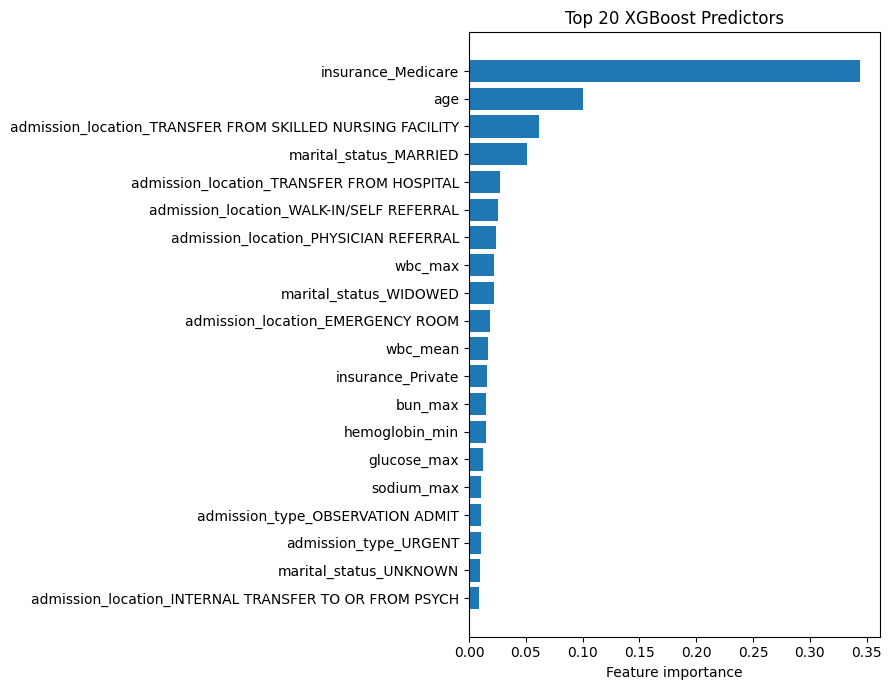

In [72]:
# Plot top 20 XGBoost predictors

top_xgb_features = xgb_importance.head(20).sort_values("importance")

plt.figure(figsize=(9, 7))

plt.barh(top_xgb_features["feature"], top_xgb_features["importance"])

plt.xlabel("Feature importance")
plt.title("Top 20 XGBoost Predictors")
plt.tight_layout()
plt.show()


## Compare Model Performance

In [73]:
# Compare validation performance across all models

results_df = pd.DataFrame(model_results)

results_df = results_df.sort_values(["PR-AUC", "ROC-AUC"], ascending=False).reset_index(
    drop=True
)

display(
    results_df.round(
        {
            "Accuracy": 3,
            "Precision": 3,
            "Recall": 3,
            "F1": 3,
            "ROC-AUC": 3,
            "PR-AUC": 3,
            "Training Time (sec)": 1,
        }
    )
)


,Model,Features,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Training Time (sec)
0,XGBoost,Full,0.817,0.654,0.284,0.396,0.814,0.556,26.3
1,XGBoost,PCA,0.814,0.643,0.266,0.376,0.809,0.543,16.8
2,Logistic Regression,Full,0.811,0.627,0.264,0.371,0.802,0.531,14.6
3,Logistic Regression,PCA,0.809,0.620,0.253,0.359,0.799,0.524,12.1
4,Random Forest,Full,0.812,0.626,0.273,0.380,0.795,0.515,172.8
5,Random Forest,PCA,0.810,0.613,0.270,0.375,0.792,0.510,171.7


In [74]:
# Compare Full vs PCA performance side-by-side

comparison_table = results_df.pivot(
    index="Model",
    columns="Features",
    values=["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"],
)

display(comparison_table.round(3))


Accuracy        Precision        Recall            F1  \
Features                Full    PCA      Full    PCA   Full    PCA   Full   
Model                                                                       
Logistic Regression    0.811  0.809     0.627  0.620  0.264  0.253  0.371   
Random Forest          0.812  0.810     0.626  0.613  0.273  0.270  0.380   
XGBoost                0.817  0.814     0.654  0.643  0.284  0.266  0.396   

                           ROC-AUC        PR-AUC         
Features               PCA    Full    PCA   Full    PCA  
Model                                                    
Logistic Regression  0.359   0.802  0.799  0.531  0.524  
Random Forest        0.375   0.795  0.792  0.515  0.510  
XGBoost              0.376   0.814  0.809  0.556  0.543

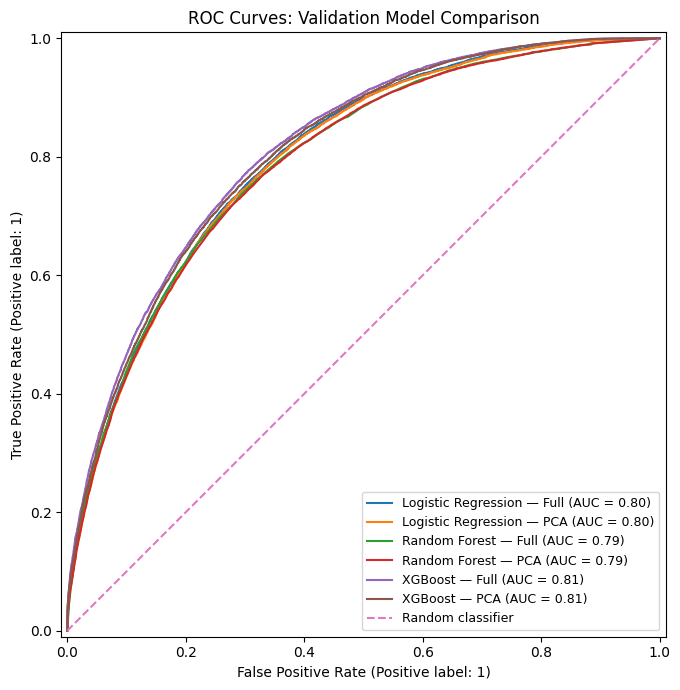

In [75]:
# ROC curves — validation set

fig, ax = plt.subplots(figsize=(9, 7))

RocCurveDisplay.from_predictions(
    y_val, logreg_full_prob, name="Logistic Regression — Full", ax=ax
)

RocCurveDisplay.from_predictions(
    y_val, logreg_pca_prob, name="Logistic Regression — PCA", ax=ax
)

RocCurveDisplay.from_predictions(
    y_val, rf_full_prob, name="Random Forest — Full", ax=ax
)

RocCurveDisplay.from_predictions(y_val, rf_pca_prob, name="Random Forest — PCA", ax=ax)

RocCurveDisplay.from_predictions(y_val, xgb_full_prob, name="XGBoost — Full", ax=ax)

RocCurveDisplay.from_predictions(y_val, xgb_pca_prob, name="XGBoost — PCA", ax=ax)

ax.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")

ax.set_title("ROC Curves: Validation Model Comparison")

ax.legend(loc="lower right", fontsize=9)

plt.tight_layout()
plt.show()


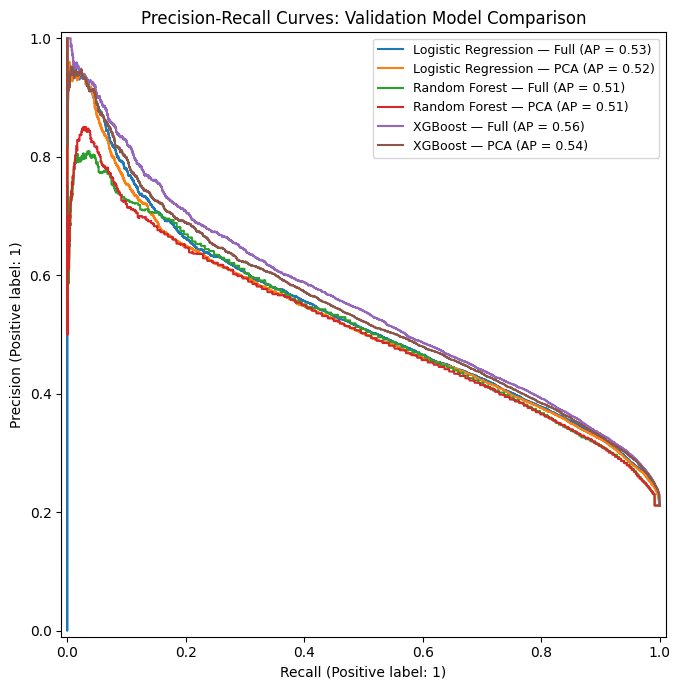

In [76]:
# Precision-Recall curves — validation set

fig, ax = plt.subplots(figsize=(9, 7))

PrecisionRecallDisplay.from_predictions(
    y_val, logreg_full_prob, name="Logistic Regression — Full", ax=ax
)

PrecisionRecallDisplay.from_predictions(
    y_val, logreg_pca_prob, name="Logistic Regression — PCA", ax=ax
)

PrecisionRecallDisplay.from_predictions(
    y_val, rf_full_prob, name="Random Forest — Full", ax=ax
)

PrecisionRecallDisplay.from_predictions(
    y_val, rf_pca_prob, name="Random Forest — PCA", ax=ax
)

PrecisionRecallDisplay.from_predictions(
    y_val, xgb_full_prob, name="XGBoost — Full", ax=ax
)

PrecisionRecallDisplay.from_predictions(
    y_val, xgb_pca_prob, name="XGBoost — PCA", ax=ax
)

ax.set_title("Precision-Recall Curves: Validation Model Comparison")

ax.legend(fontsize=9)

plt.tight_layout()
plt.show()


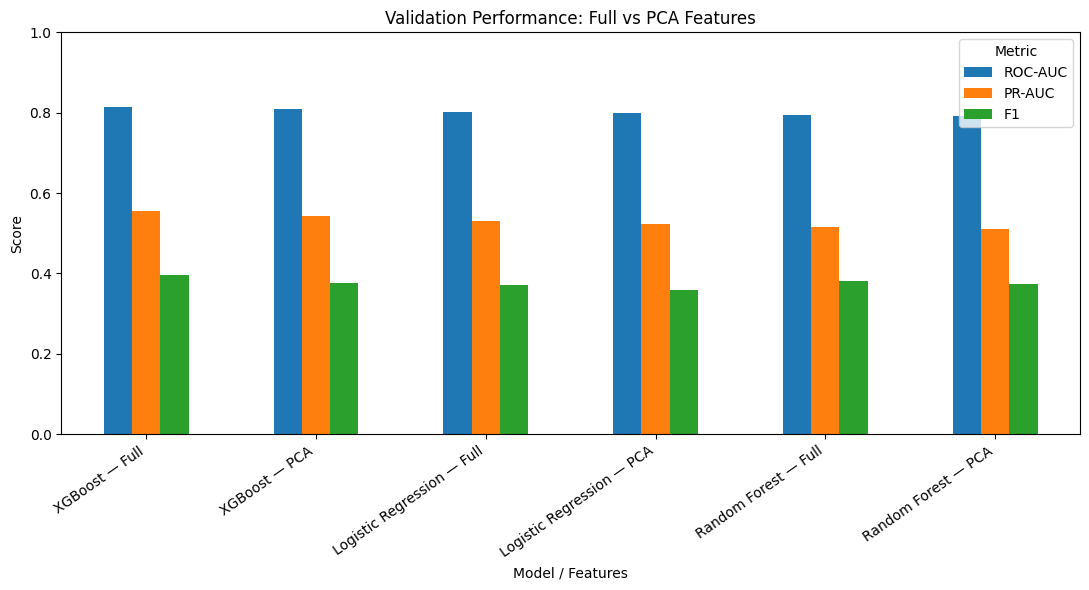

In [77]:
# Visual comparison of validation model performance

plot_results = results_df.copy()

plot_results["Model / Features"] = (
    plot_results["Model"] + " — " + plot_results["Features"]
)

metrics_to_plot = ["ROC-AUC", "PR-AUC", "F1"]

plot_data = plot_results.set_index("Model / Features")[metrics_to_plot]

ax = plot_data.plot(kind="bar", figsize=(11, 6))

ax.set_ylabel("Score")

ax.set_ylim(0, 1)

ax.set_title("Validation Performance: Full vs PCA Features")

plt.xticks(rotation=35, ha="right")

plt.legend(title="Metric")

plt.tight_layout()
plt.show()


### Comparing the Six Model Configurations

Across the validation set, **XGBoost with the full feature representation** has the strongest overall performance:

- Accuracy: **0.817**
- Precision: **0.654**
- Recall: **0.284**
- F1: **0.396**
- ROC-AUC: **0.814**
- PR-AUC: **0.556**

XGBoost-Full has the highest PR-AUC and ROC-AUC of the six configurations and is therefore selected for the next stage.

A second consistent result is that **the full laboratory representation slightly outperforms PCA for all three model types**. PCA reduces 36 laboratory variables to only 9 components while retaining 95% of their variance, but this does not translate into improved outcome prediction.

This illustrates an important distinction: **preserving variance is not the same as preserving all predictive information**. PCA is useful for dimensionality reduction, but tree-based models in particular may benefit from having access to the original laboratory variables and their nonlinear relationships.

All six models also show low facility-discharge recall at the default 0.50 threshold. Because ROC-AUC and PR-AUC indicate useful discrimination despite this low recall, the next step examines whether the classification threshold is contributing to the problem.

## Threshold Sensitivity Analysis

A classifier first produces a **probability**, not a final class label. The commonly used threshold of 0.50 labels a patient as facility-based only when the predicted probability is at least 50%.

That threshold is not automatically appropriate for every clinical use case.

For this project, one possible use of the model would be to identify patients who may benefit from early discharge-planning review. In that setting, missing a patient who eventually requires facility-based care may be more costly than reviewing some patients who ultimately return home.

We therefore examine how changing the threshold affects:

- **Precision:** among patients flagged as facility-based, how many actually have a facility-based discharge?
- **Recall:** among patients who actually have a facility-based discharge, how many are identified?
- **Specificity:** among patients who ultimately go home, how many are correctly left unflagged?
- **F1:** balance between precision and recall.
- **Flagged (%):** percentage of all admissions classified as facility-based and therefore potentially sent for additional review.

Lower thresholds increase recall but also increase the number of false positives and the operational workload represented by Flagged (%).

In [78]:
# Select the best model configuration using validation results
# We prioritize PR-AUC because facility-based discharge is
# the minority class, with ROC-AUC used as a secondary measure.

selected_configuration = results_df.sort_values(
    ["PR-AUC", "ROC-AUC"], ascending=False
).iloc[0]

selected_model_name = selected_configuration["Model"]

selected_feature_set = selected_configuration["Features"]

print("Selected model:", selected_model_name)

print("Selected feature representation:", selected_feature_set)

print(f"Validation PR-AUC: " f"{selected_configuration['PR-AUC']:.3f}")

print(f"Validation ROC-AUC: " f"{selected_configuration['ROC-AUC']:.3f}")


Selected model: XGBoost
Selected feature representation: Full
Validation PR-AUC: 0.556
Validation ROC-AUC: 0.814


In [79]:
# Threshold sensitivity analysis for XGBoost — Full

from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

thresholds = np.arange(0.10, 0.51, 0.02)

threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (xgb_full_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_val, y_pred_threshold).ravel()

    precision = precision_score(y_val, y_pred_threshold, zero_division=0)

    recall = recall_score(y_val, y_pred_threshold)

    f1 = f1_score(y_val, y_pred_threshold)

    specificity = tn / (tn + fp)

    flagged_pct = y_pred_threshold.mean() * 100

    threshold_results.append(
        {
            "Threshold": threshold,
            "Precision": precision,
            "Recall": recall,
            "F1": f1,
            "Specificity": specificity,
            "Flagged (%)": flagged_pct,
        }
    )


threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(3))


,Threshold,Precision,Recall,F1,Specificity,Flagged (%)
0,0.10,0.312,0.930,0.468,0.451,62.950
1,0.12,0.331,0.902,0.484,0.511,57.625
2,0.14,0.350,0.871,0.500,0.566,52.610
3,0.16,0.368,0.843,0.512,0.612,48.422
4,0.18,0.385,0.814,0.522,0.651,44.721
5,0.20,0.402,0.781,0.531,0.688,41.110
6,0.22,0.417,0.748,0.536,0.720,37.898
7,0.24,0.433,0.714,0.539,0.750,34.836
8,0.26,0.450,0.680,0.542,0.778,31.912
9,0.28,0.466,0.645,0.541,0.802,29.251


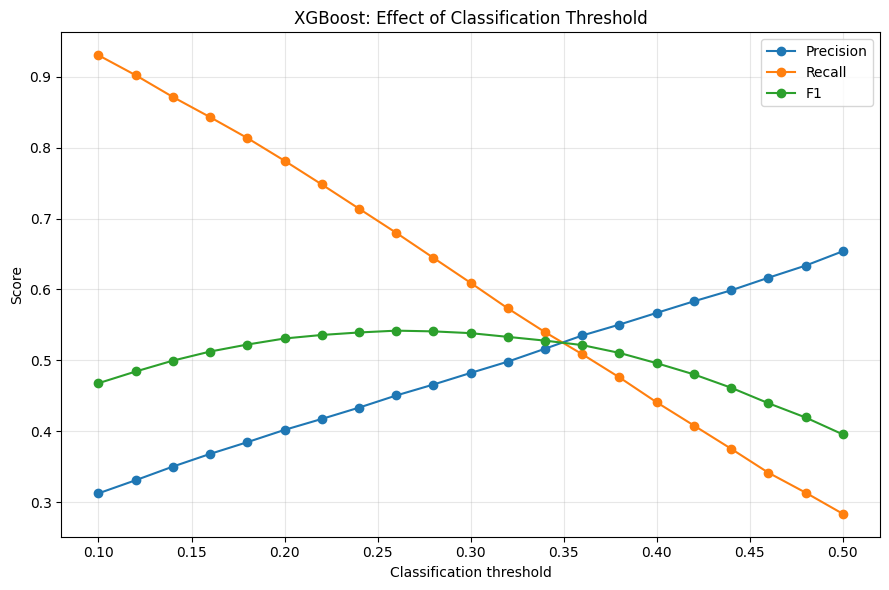

In [80]:
# Precision / Recall / F1 across classification thresholds

plt.figure(figsize=(9, 6))

plt.plot(
    threshold_df["Threshold"], threshold_df["Precision"], marker="o", label="Precision"
)

plt.plot(threshold_df["Threshold"], threshold_df["Recall"], marker="o", label="Recall")

plt.plot(threshold_df["Threshold"], threshold_df["F1"], marker="o", label="F1")

plt.xlabel("Classification threshold")
plt.ylabel("Score")
plt.title("XGBoost: Effect of Classification Threshold")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [81]:
# Show a few clinically useful candidate thresholds

candidate_thresholds = [0.50, 0.40, 0.35, 0.30, 0.25, 0.20]

candidate_results = []

for threshold in candidate_thresholds:

    y_pred_threshold = (xgb_full_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_val, y_pred_threshold).ravel()

    candidate_results.append(
        {
            "Threshold": threshold,
            "Precision": precision_score(y_val, y_pred_threshold),
            "Recall": recall_score(y_val, y_pred_threshold),
            "F1": f1_score(y_val, y_pred_threshold),
            "Specificity": tn / (tn + fp),
            "Flagged (%)": y_pred_threshold.mean() * 100,
        }
    )

candidate_results = pd.DataFrame(candidate_results)

display(candidate_results.round(3))


,Threshold,Precision,Recall,F1,Specificity,Flagged (%)
0,0.50,0.654,0.284,0.396,0.960,9.172
1,0.40,0.567,0.441,0.496,0.910,16.441
2,0.35,0.527,0.524,0.525,0.874,21.050
3,0.30,0.482,0.609,0.538,0.825,26.715
4,0.25,0.441,0.696,0.540,0.764,33.351
5,0.20,0.402,0.781,0.531,0.688,41.110


In [82]:
# Find candidate operating points for target recall levels

for target_recall in [0.50, 0.60, 0.70, 0.80]:

    candidates = threshold_df[threshold_df["Recall"] >= target_recall]

    if len(candidates) > 0:

        # Highest threshold that still reaches target recall
        selected = candidates.sort_values("Threshold", ascending=False).iloc[0]

        print(
            f"Target recall >= {target_recall:.0%}: "
            f"threshold={selected['Threshold']:.2f}, "
            f"precision={selected['Precision']:.3f}, "
            f"recall={selected['Recall']:.3f}, "
            f"specificity={selected['Specificity']:.3f}, "
            f"flagged={selected['Flagged (%)']:.1f}%"
        )


Target recall >= 50%: threshold=0.36, precision=0.535, recall=0.509, specificity=0.882, flagged=20.1%
Target recall >= 60%: threshold=0.30, precision=0.482, recall=0.609, specificity=0.825, flagged=26.7%
Target recall >= 70%: threshold=0.24, precision=0.433, recall=0.714, specificity=0.750, flagged=34.8%
Target recall >= 80%: threshold=0.18, precision=0.385, recall=0.814, specificity=0.651, flagged=44.7%


### Selecting an Operating Threshold

At the default threshold of 0.50, XGBoost-Full identifies only **28.4%** of facility-based discharges and flags just **9.2%** of admissions.

As the threshold is lowered, recall increases substantially:

- threshold 0.36: recall ≈ **50.9%**
- threshold 0.30: recall ≈ **60.9%**
- threshold 0.24: recall ≈ **71.4%**
- threshold 0.18: recall ≈ **81.4%**

The tradeoff is decreasing precision and specificity, along with a larger percentage of admissions being flagged.

For this tutorial, we define the operating objective **before looking at the final test outcomes**: achieve at least **60% recall** while keeping the threshold as high as possible. The validation data therefore select a threshold of **0.30**.

At this threshold, validation performance is:

- Precision: **0.482**
- Recall: **0.609**
- Specificity: **0.825**
- F1: **0.538**
- Flagged: **26.7%**

This threshold is not presented as a universally optimal clinical cutoff. A real deployment would choose an operating point based on clinical workflow, staffing capacity, and the relative consequences of false negatives and false positives.

In [83]:
# Select classification threshold using VALIDATION data
# Clinical objective:
# Achieve at least 60% recall while keeping the threshold
# as high as possible.

target_recall = 0.60

eligible_thresholds = threshold_df[threshold_df["Recall"] >= target_recall]

selected_threshold_row = eligible_thresholds.sort_values(
    "Threshold", ascending=False
).iloc[0]

selected_threshold = float(selected_threshold_row["Threshold"])

print(f"Selected threshold: " f"{selected_threshold:.2f}")

print(f"Validation precision: " f"{selected_threshold_row['Precision']:.3f}")

print(f"Validation recall: " f"{selected_threshold_row['Recall']:.3f}")

print(f"Validation specificity: " f"{selected_threshold_row['Specificity']:.3f}")

print(f"Validation F1: " f"{selected_threshold_row['F1']:.3f}")

print(f"Patients flagged: " f"{selected_threshold_row['Flagged (%)']:.1f}%")


Selected threshold: 0.30
Validation precision: 0.482
Validation recall: 0.609
Validation specificity: 0.825
Validation F1: 0.538
Patients flagged: 26.7%


## Final Model Training

Model selection and threshold selection are now complete:

- **Algorithm:** XGBoost
- **Feature representation:** Full
- **Classification threshold:** 0.30

The selected configuration is now refitted using **all development data**, combining the original subtraining and validation patients.

Because preprocessing parameters were originally learned only from the subtraining set, they are also refitted using the entire training/development set. The final training data therefore determine the clipping limits, imputation values, categorical encoding, and scaling parameters.

Those fixed transformations are then applied to the held-out test predictors.

No model or threshold choices are changed after evaluating the test outcomes. This preserves the test set as an independent final assessment of generalization.

In [84]:
# Prepare raw FINAL training and test predictors
# train_df = all development patients
# test_df  = untouched final test patients

X_train_final_raw = train_df[feature_columns].copy()

X_test_final_raw = test_df[feature_columns].copy()

y_train_final = train_df[target_column].copy()

# y_test already exists from the original outer split.
# Do not use it until final evaluation.

print("Final training observations:", X_train_final_raw.shape)

print("Final test observations:", X_test_final_raw.shape)


Final training observations: (280576, 42)
Final test observations: (70123, 42)


In [85]:
# Fit outlier clipping thresholds using ALL training data

final_lower_bounds = X_train_final_raw[lab_columns].quantile(0.01)

final_upper_bounds = X_train_final_raw[lab_columns].quantile(0.99)

X_train_final_clipped = X_train_final_raw.copy()

X_test_final_clipped = X_test_final_raw.copy()

# Apply training-derived limits to training data
X_train_final_clipped[lab_columns] = X_train_final_clipped[lab_columns].clip(
    lower=final_lower_bounds, upper=final_upper_bounds, axis=1
)

# Apply the SAME limits to the untouched test data
X_test_final_clipped[lab_columns] = X_test_final_clipped[lab_columns].clip(
    lower=final_lower_bounds, upper=final_upper_bounds, axis=1
)


In [86]:
# Numerical median imputation
# Learn medians from ALL training data only.

final_numeric_imputer = SimpleImputer(strategy="median")

X_train_final_numeric = pd.DataFrame(
    final_numeric_imputer.fit_transform(X_train_final_clipped[numerical_features]),
    columns=numerical_features,
    index=X_train_final_clipped.index,
)

X_test_final_numeric = pd.DataFrame(
    final_numeric_imputer.transform(X_test_final_clipped[numerical_features]),
    columns=numerical_features,
    index=X_test_final_clipped.index,
)


In [87]:
# Categorical missing-value handling

final_categorical_imputer = SimpleImputer(strategy="constant", fill_value="UNKNOWN")

train_cat_input = (
    X_train_final_clipped[categorical_features]
    .astype("object")
    .replace({pd.NA: np.nan})
)

test_cat_input = (
    X_test_final_clipped[categorical_features].astype("object").replace({pd.NA: np.nan})
)

X_train_final_categorical = pd.DataFrame(
    final_categorical_imputer.fit_transform(train_cat_input),
    columns=categorical_features,
    index=X_train_final_clipped.index,
)

X_test_final_categorical = pd.DataFrame(
    final_categorical_imputer.transform(test_cat_input),
    columns=categorical_features,
    index=X_test_final_clipped.index,
)


In [88]:
# One-hot encoding

final_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

X_train_final_encoded_array = final_encoder.fit_transform(X_train_final_categorical)

X_test_final_encoded_array = final_encoder.transform(X_test_final_categorical)

final_encoded_feature_names = final_encoder.get_feature_names_out(categorical_features)

X_train_final_encoded = pd.DataFrame(
    X_train_final_encoded_array,
    columns=final_encoded_feature_names,
    index=X_train_final_clipped.index,
)

X_test_final_encoded = pd.DataFrame(
    X_test_final_encoded_array,
    columns=final_encoded_feature_names,
    index=X_test_final_clipped.index,
)


In [89]:
# Standardize numerical predictors
# Scaling parameters are learned from ALL training data only.

final_scaler = StandardScaler()

X_train_final_numeric_scaled = pd.DataFrame(
    final_scaler.fit_transform(X_train_final_numeric),
    columns=numerical_features,
    index=X_train_final_numeric.index,
)

X_test_final_numeric_scaled = pd.DataFrame(
    final_scaler.transform(X_test_final_numeric),
    columns=numerical_features,
    index=X_test_final_numeric.index,
)


In [90]:
# Construct final FULL feature representation

X_train_final = pd.concat([X_train_final_numeric_scaled, X_train_final_encoded], axis=1)

X_test_final = pd.concat([X_test_final_numeric_scaled, X_test_final_encoded], axis=1)

print("Final training matrix:", X_train_final.shape)

print("Final test matrix:", X_test_final.shape)

print("\nMissing training values:", X_train_final.isna().sum().sum())

print("Missing test values:", X_test_final.isna().sum().sum())

print(
    "\nSame feature columns:", list(X_train_final.columns) == list(X_test_final.columns)
)

assert X_train_final.isna().sum().sum() == 0

assert X_test_final.isna().sum().sum() == 0

assert list(X_train_final.columns) == list(X_test_final.columns)

print("\nFinal preprocessing checks passed.")


Final training matrix: (280576, 70)
Final test matrix: (70123, 70)

Missing training values: 0
Missing test values: 0

Same feature columns: True

Final preprocessing checks passed.


In [91]:
# Train FINAL selected model
# Model configuration was chosen using validation data.
# The model is now refitted using ALL training patients.

final_xgb = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
)

final_xgb.fit(X_train_final, y_train_final)

print("Final XGBoost model trained using all development patients.")


Final XGBoost model trained using all development patients.


In [92]:
from sklearn.metrics import balanced_accuracy_score

# FINAL TEST EVALUATION
# Model type, feature representation, preprocessing,
# hyperparameters, and classification threshold have all
# already been fixed using training/validation data

# Predict probabilities on the untouched test patients
final_test_prob = final_xgb.predict_proba(X_test_final)[:, 1]

# Apply the threshold selected on VALIDATION data
final_test_pred = (final_test_prob >= selected_threshold).astype(int)


# Confusion matrix components
tn, fp, fn, tp = confusion_matrix(y_test, final_test_pred).ravel()

final_specificity = tn / (tn + fp)

# Final performance metrics
final_results = pd.DataFrame(
    [
        {
            "Model": "XGBoost",
            "Features": "Full",
            "Threshold": selected_threshold,
            "Accuracy": accuracy_score(y_test, final_test_pred),
            "Balanced Accuracy": balanced_accuracy_score(y_test, final_test_pred),
            "Precision": precision_score(y_test, final_test_pred, zero_division=0),
            "Recall": recall_score(y_test, final_test_pred),
            "Specificity": final_specificity,
            "F1": f1_score(y_test, final_test_pred),
            "ROC-AUC": roc_auc_score(y_test, final_test_prob),
            "PR-AUC": average_precision_score(y_test, final_test_prob),
            "Flagged (%)": final_test_pred.mean() * 100,
        }
    ]
)

display(final_results.round(3))


,Model,Features,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,F1,ROC-AUC,PR-AUC,Flagged (%)
0,XGBoost,Full,0.3,0.775,0.721,0.487,0.626,0.816,0.548,0.814,0.564,28.034


                precision    recall  f1-score   support

    Home-based       0.89      0.82      0.85     54852
Facility-based       0.49      0.63      0.55     15271

      accuracy                           0.77     70123
     macro avg       0.69      0.72      0.70     70123
  weighted avg       0.80      0.77      0.78     70123

True negatives : 44,759
False positives: 10,093
False negatives: 5,706
True positives : 9,565


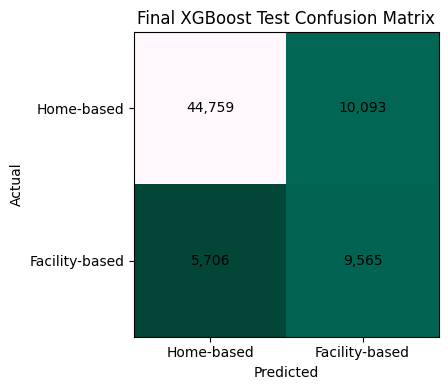

In [93]:
# Detailed final test results

print(
    classification_report(
        y_test, final_test_pred, target_names=["Home-based", "Facility-based"]
    )
)

print(f"True negatives : {tn:,}")

print(f"False positives: {fp:,}")

print(f"False negatives: {fn:,}")

print(f"True positives : {tp:,}")


cm = np.array([[tn, fp], [fn, tp]])

plt.figure(figsize=(5, 4))

plt.imshow(cm, cmap="PuBuGn_r")

plt.xticks([0, 1], ["Home-based", "Facility-based"])

plt.yticks([0, 1], ["Home-based", "Facility-based"])

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("Final XGBoost Test Confusion Matrix")

for i in range(2):
    for j in range(2):

        plt.text(j, i, f"{cm[i, j]:,}", ha="center", va="center")

plt.tight_layout()
plt.show()


### Final Held-Out Test Performance

The final XGBoost model is evaluated on **70,123 hospitalizations from patients who were not used during model or threshold selection**.

At the validation-selected threshold of 0.30, final test performance is:

- **Accuracy:** 0.775
- **Balanced accuracy:** 0.721
- **Precision:** 0.487
- **Recall:** 0.626
- **Specificity:** 0.816
- **F1:** 0.548
- **ROC-AUC:** 0.814
- **PR-AUC:** 0.564
- **Flagged:** 28.0%

The confusion matrix shows:

- 44,759 true negatives,
- 10,093 false positives,
- 5,706 false negatives,
- 9,565 true positives.

The model therefore identifies approximately **62.6% of patients who ultimately have a facility-based discharge**, while correctly leaving approximately **81.6% of home-based discharges unflagged**.

Precision of 48.7% means that roughly half of the admissions flagged by the model actually have a facility-based discharge. Because 28.0% of all admissions are flagged, this percentage also provides an estimate of the potential screening workload if the model were used to trigger additional discharge-planning review.

Validation performance was used to select XGBoost with the full feature set and to choose the classification threshold. The selected preprocessing steps and model were then refitted using all training patients. The held-out test set was evaluated only after these decisions were finalized.

In [94]:
# Compare default and selected classification thresholds

threshold_comparison = []

for threshold in [0.50, selected_threshold]:

    pred = (final_test_prob >= threshold).astype(int)

    tn_t, fp_t, fn_t, tp_t = confusion_matrix(y_test, pred).ravel()

    threshold_comparison.append(
        {
            "Threshold": threshold,
            "Accuracy": accuracy_score(y_test, pred),
            "Balanced Accuracy": balanced_accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred),
            "Specificity": tn_t / (tn_t + fp_t),
            "F1": f1_score(y_test, pred),
            "Flagged (%)": pred.mean() * 100,
        }
    )

threshold_comparison_df = pd.DataFrame(threshold_comparison)

display(threshold_comparison_df.round(3))


,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,F1,Flagged (%)
0,0.5,0.813,0.625,0.658,0.291,0.958,0.404,9.647
1,0.3,0.775,0.721,0.487,0.626,0.816,0.548,28.034


### Effect of the Selected Threshold

The probability-ranking ability of the model does not change when the classification threshold changes; ROC-AUC and PR-AUC are based on predicted probabilities across possible thresholds.

What changes is the operating tradeoff.

At the default **0.50** threshold:

- Accuracy = **0.813**
- Recall = **0.291**
- Precision = **0.658**
- F1 = **0.404**
- Flagged = **9.6%**

At the selected **0.30** threshold:

- Accuracy = **0.775**
- Recall = **0.626**
- Precision = **0.487**
- F1 = **0.548**
- Flagged = **28.0%**

The lower threshold sacrifices some overall accuracy and precision in exchange for identifying more than twice as many of the eventual facility-based discharges.

This is especially important because home-based discharge is the majority outcome. A classifier could obtain relatively high accuracy by predicting home-based discharge for nearly everyone while providing little value for identifying the minority facility-based group. Balanced accuracy, recall, F1, and PR-AUC therefore provide important context beyond ordinary accuracy.

This comparison is descriptive only. The 0.30 threshold was selected using validation data before the final test evaluation and is not changed based on these test results.

In [95]:
# Compare final model with a majority-class baseline
# A majority-class classifier predicts Home-based for every
# admission because Home-based is the more common outcome.

test_facility_prevalence = y_test.mean()

majority_accuracy = max(test_facility_prevalence, 1 - test_facility_prevalence)

print(f"Facility-based prevalence in test set: " f"{test_facility_prevalence:.3f}")

print(f"Home-based prevalence in test set: " f"{1 - test_facility_prevalence:.3f}")

print(f"Majority-class accuracy: " f"{majority_accuracy:.3f}")

print(f"Final model accuracy: " f"{accuracy_score(y_test, final_test_pred):.3f}")

print(
    f"Final model balanced accuracy: "
    f"{balanced_accuracy_score(y_test, final_test_pred):.3f}"
)


Facility-based prevalence in test set: 0.218
Home-based prevalence in test set: 0.782
Majority-class accuracy: 0.782
Final model accuracy: 0.775
Final model balanced accuracy: 0.721


### Why Accuracy Alone Is Misleading

Because **78.2%** of test admissions end in a home-based discharge, a trivial classifier that predicts "Home-based" for every patient would achieve **78.2% accuracy**.

That is slightly higher than the final model's **77.5% accuracy**, but the trivial classifier would identify **none** of the patients who ultimately have a facility-based discharge.

The selected XGBoost model instead achieves:

- **62.6% recall** for facility-based discharge,
- **81.6% specificity** for home-based discharge,
- **72.1% balanced accuracy**.

Balanced accuracy gives equal importance to performance in both outcome classes. A classifier predicting Home-based for everyone would have a balanced accuracy of only **50%**.

This illustrates why overall accuracy can be misleading when one outcome is substantially more common than the other. For this screening-oriented use case, recall, specificity, balanced accuracy, F1, and precision-recall performance provide more useful context.

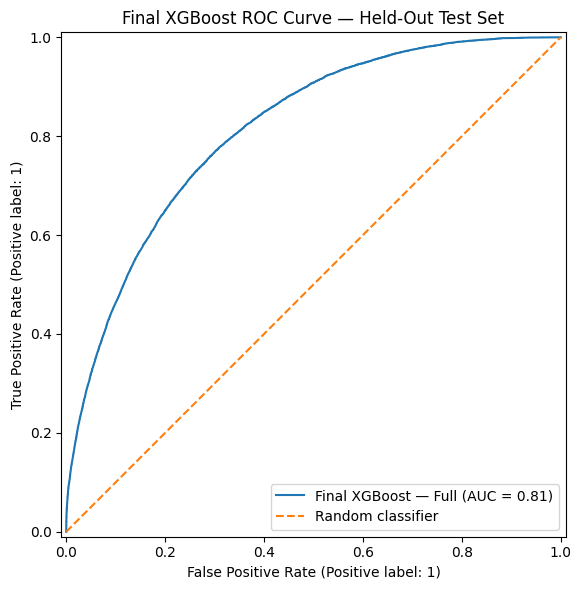

In [96]:
# Final selected model — ROC curve on held-out test set

fig, ax = plt.subplots(figsize=(7, 6))

RocCurveDisplay.from_predictions(
    y_test, final_test_prob, name="Final XGBoost — Full", ax=ax
)

ax.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")

ax.set_title("Final XGBoost ROC Curve — Held-Out Test Set")

ax.legend()

plt.tight_layout()
plt.show()


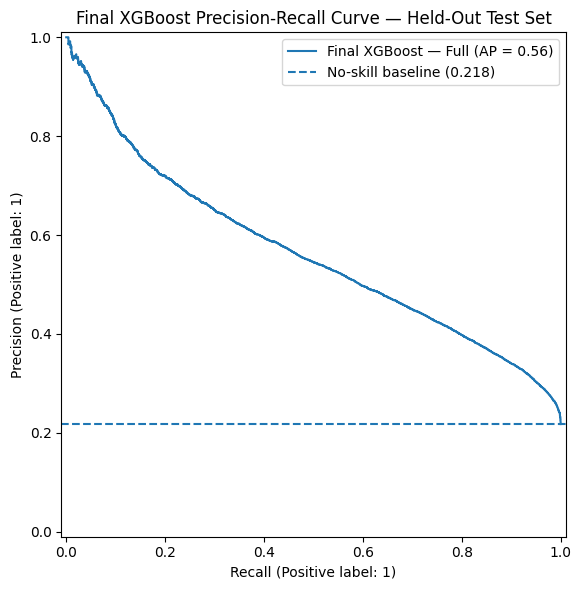

In [97]:
# Final selected model — Precision-Recall curve
# on held-out test set

fig, ax = plt.subplots(figsize=(7, 6))

PrecisionRecallDisplay.from_predictions(
    y_test, final_test_prob, name="Final XGBoost — Full", ax=ax
)

# Positive-class prevalence gives the no-skill PR baseline
baseline_precision = y_test.mean()

ax.axhline(
    baseline_precision,
    linestyle="--",
    label=f"No-skill baseline ({baseline_precision:.3f})",
)

ax.set_title("Final XGBoost Precision-Recall Curve — Held-Out Test Set")

ax.legend()

plt.tight_layout()
plt.show()


In [98]:
# Feature importance from FINAL refitted XGBoost model

final_xgb_importance = pd.DataFrame(
    {"feature": X_train_final.columns, "importance": final_xgb.feature_importances_}
)

final_xgb_importance = final_xgb_importance.sort_values(
    "importance", ascending=False
).reset_index(drop=True)

display(final_xgb_importance.head(20))


,feature,importance
0,insurance_Medicare,0.339604
1,age,0.101829
2,admission_location_TRANSFER FROM SKILLED NURSI...,0.060763
3,marital_status_MARRIED,0.058772
4,admission_location_WALK-IN/SELF REFERRAL,0.029974
5,admission_location_TRANSFER FROM HOSPITAL,0.027264
6,admission_location_PHYSICIAN REFERRAL,0.026217
7,wbc_max,0.021949
8,marital_status_WIDOWED,0.018848
9,bun_max,0.018397


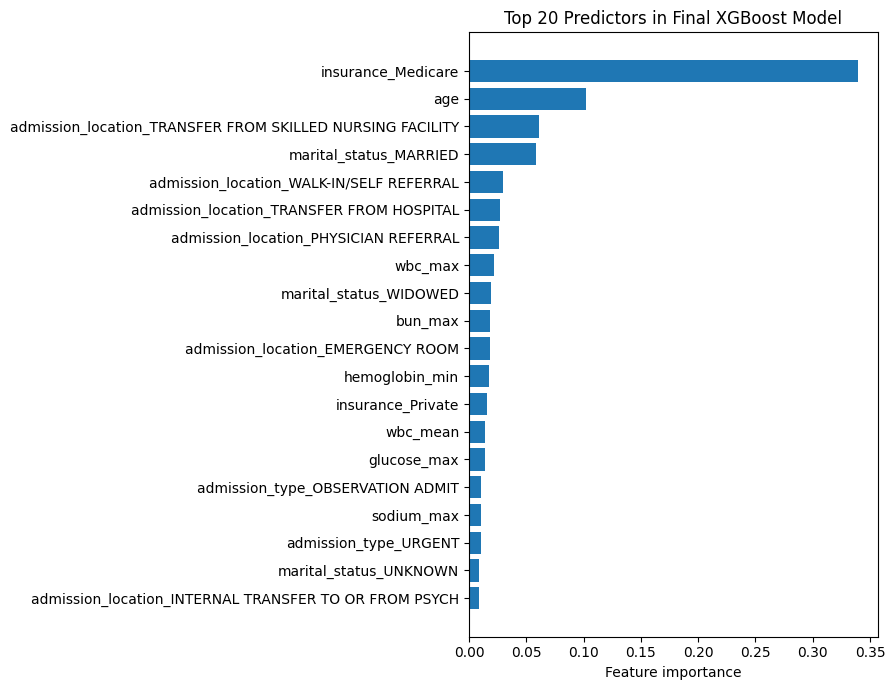

In [99]:
# Top 20 predictors in final XGBoost model

top_final_features = final_xgb_importance.head(20).sort_values("importance")

plt.figure(figsize=(9, 7))

plt.barh(top_final_features["feature"], top_final_features["importance"])

plt.xlabel("Feature importance")

plt.title("Top 20 Predictors in Final XGBoost Model")

plt.tight_layout()
plt.show()


## Limitations

This tutorial demonstrates a machine-learning workflow, but several limitations should be considered when interpreting the results.

**Observed destination rather than clinical need:** The outcome represents the recorded discharge location. It does not determine whether a patient developed a new need for post-acute care. Patients may return to a facility where they lived before admission.

**Limited predictor set:** The model intentionally uses a small set of admission variables and nine common laboratory tests. Important determinants of discharge destination such as functional status, mobility, cognitive status, comorbidities, social support, housing, insurance authorization, therapy evaluations, and caregiver availability are not directly represented.

**Admission location can act as a strong proxy:** Patients transferred from skilled nursing facilities frequently return to facility-based care. This is valid information available at admission, but it means some predictive performance reflects knowledge of the patient's pre-admission setting rather than first-day physiology alone.

**Missing laboratory data are informative:** Facility-bound patients had more complete first-day laboratory testing. Median imputation preserves the cohort but does not explicitly model the information contained in whether a test was ordered. Adding missingness indicators would be a reasonable future experiment.

**Extreme-value handling:** Laboratory features are clipped at training-derived 1st and 99th percentiles. This limits the influence of extreme observations but may also compress genuine severe physiological values.

**PCA interpretation:** PCA retains at least 95% of laboratory variance but slightly reduces predictive performance in this analysis. The principal components are also less clinically interpretable than the original laboratory variables.

**Threshold choice:** The 0.30 threshold was selected to achieve at least 60% recall on the validation set. This is an illustrative screening objective rather than a clinically validated operating threshold.

**No extensive hyperparameter optimization:** The three model families are compared using reasonable fixed configurations rather than a large tuning search. Additional tuning could change absolute performance.

**Predictive rather than causal analysis:** Feature coefficients and importance scores describe associations used by the models. They do not show that a variable causes a patient to be discharged to a facility.

**Generalizability:** Performance is measured within MIMIC-IV and should not be assumed to transfer directly to other hospitals, patient populations, or discharge-planning workflows without external validation.

The model should therefore be viewed as a demonstration of early risk stratification and machine-learning methodology rather than a ready-to-deploy clinical decision system.

## Conclusion

This tutorial asked whether information available within the first 24 hours of hospitalization could help predict whether an adult patient would ultimately have a home-based or facility-based discharge.

Several findings emerged:

1. Admission context and age show strong associations with discharge destination, while several first-day laboratory measurements also differ between the two outcome groups and contribute to the fitted models.
2. The 36 laboratory summaries are highly correlated, allowing PCA to reduce them to 9 components while retaining at least 95% of their variance.
3. Despite this dimensionality reduction, the original laboratory features performed slightly better than PCA features for Logistic Regression, Random Forest, and XGBoost.
4. XGBoost using the full feature representation produced the strongest validation discrimination and was selected as the final model.
5. The default 0.50 threshold produced high precision but missed most facility-based discharges.
6. Selecting a threshold of 0.30 on the validation set increased recall to approximately 60%, and the final held-out test set produced **62.6% recall, 81.6% specificity, ROC-AUC 0.814, and PR-AUC 0.564**.
7. The threshold experiment demonstrates that evaluating a healthcare classifier requires considering the intended use of the model rather than relying on accuracy alone.

Overall, the results suggest that early hospitalization data contain meaningful information about eventual discharge destination, but the model is not sufficient to determine placement decisions on its own. A more complete future model could incorporate functional, clinical, social, and care-planning information and would require external validation before any clinical use.